# 05 Python项目实战之数据分析

本章依据桌面讲义《第5章 - Python项目实战之数据分析》整理。上一章用网络机器人获取电影数据，本章学习怎样把表格里的数据变成有意义的统计结果和图表。

本章分为四部分：

| 部分 | 主要内容 | 学完后能够完成的事情 |
| --- | --- | --- |
| 环境准备 | Jupyter Notebook、依赖与运行方式 | 在同一个文档里编写代码、查看结果、记录分析过程 |
| Pandas 基础 | DataFrame、Series、读写、查看、筛选、清洗、排序、分组 | 把原始表格整理成适合分析的数据 |
| Matplotlib 基础 | 图表组成、折线图、柱状图、饼图、子图 | 根据问题选择图形，设置标题、坐标轴、图例 |
| 综合案例 | TMDB-TOP300 电影、连锁店销售订单 | 从数据准备走到统计、绘图、结果核验 |

**阅读说明：**保留讲义中的概念、API、案例、代码和复习题，合并重复展示页。正文中的说明用于把课件展开成可以连续阅读的笔记；课件之外为运行案例而增加的素材、参考实现，以及修正错误的地方，分别标为“补充”或“勘误”。图片内嵌，可离线查看；不设置页内跳转或手写锚点。

本章仍采用阅读型 Notebook：代码放在 Markdown 代码块里，便于边看边学。要执行时，把相应代码复制到新的 **Code 单元格**或 Python 文件。各节会说明所用数据，不要把所有示例直接拼成一个脚本。

**素材说明：**桌面 PPT 没有附带完整电影 CSV 或销售 CSV。笔记保留课件图表，并从能辨认的截图转写了 **19 条电影、10 条销售订单**作为补充练习素材。它们不是完整 TOP300 或完整连锁店数据；参考程序的输出标题也会标明“教学样例”和实际记录数。

## 一、数据分析：从表格到结论

### 1. 什么是数据分析

数据分析是从一堆杂乱的信息或数据中，通过清洗、分析、可视化等手段，找出有价值的信息和结论，从而帮助解决实际问题。

讲义列举的例子包括用户订单分析、电影榜单分析、学校学生成绩分析。三种场景使用的数据不同，但过程相似：

```text
数据收集 → 数据清洗处理 → 数据分析 → 数据可视化
```

| 环节 | 做什么 | 本章例子 |
| --- | --- | --- |
| 数据收集 | 获得原始数据 | 读取 CSV、Excel 或上一章采集的电影表 |
| 数据清洗处理 | 处理重复、缺失、异常和不一致的格式 | 识别缺失城市、负单价、不同写法的日期 |
| 数据分析 | 按目标计算数量、总和、平均值等 | 统计各语言电影数量、每天销售额 |
| 数据可视化 | 让统计关系更容易观察 | 用折线图看变化、柱状图比较数量、饼图看比例 |

**Pandas** 主要负责表格数据的读取、整理和统计；**Matplotlib** 主要负责绘图。不能用一张漂亮图表替代前面的数据核验，原始值或统计口径错误，图表同样会出错。

### 2. 先把业务问题说清楚

“哪个城市卖得最多”至少可以有三种含义：卖出的件数最多、订单数最多、销售额最高。它们对应的计算并不相同。

| 指标 | 计算方法 | 单位 |
| --- | --- | --- |
| 销售数量 | 把“销售数量”列相加 | 件 |
| 销售额 | 先算每行的数量 × 单价，再求和 | 元 |
| 订单数 | 按订单粒度计数，必要时对订单号去重 | 单 |
| 数据行数 | 表里有多少行记录 | 行 |

一张订单可能包含多件商品，也可能有多条商品明细，所以“件、单、行”不能互换。

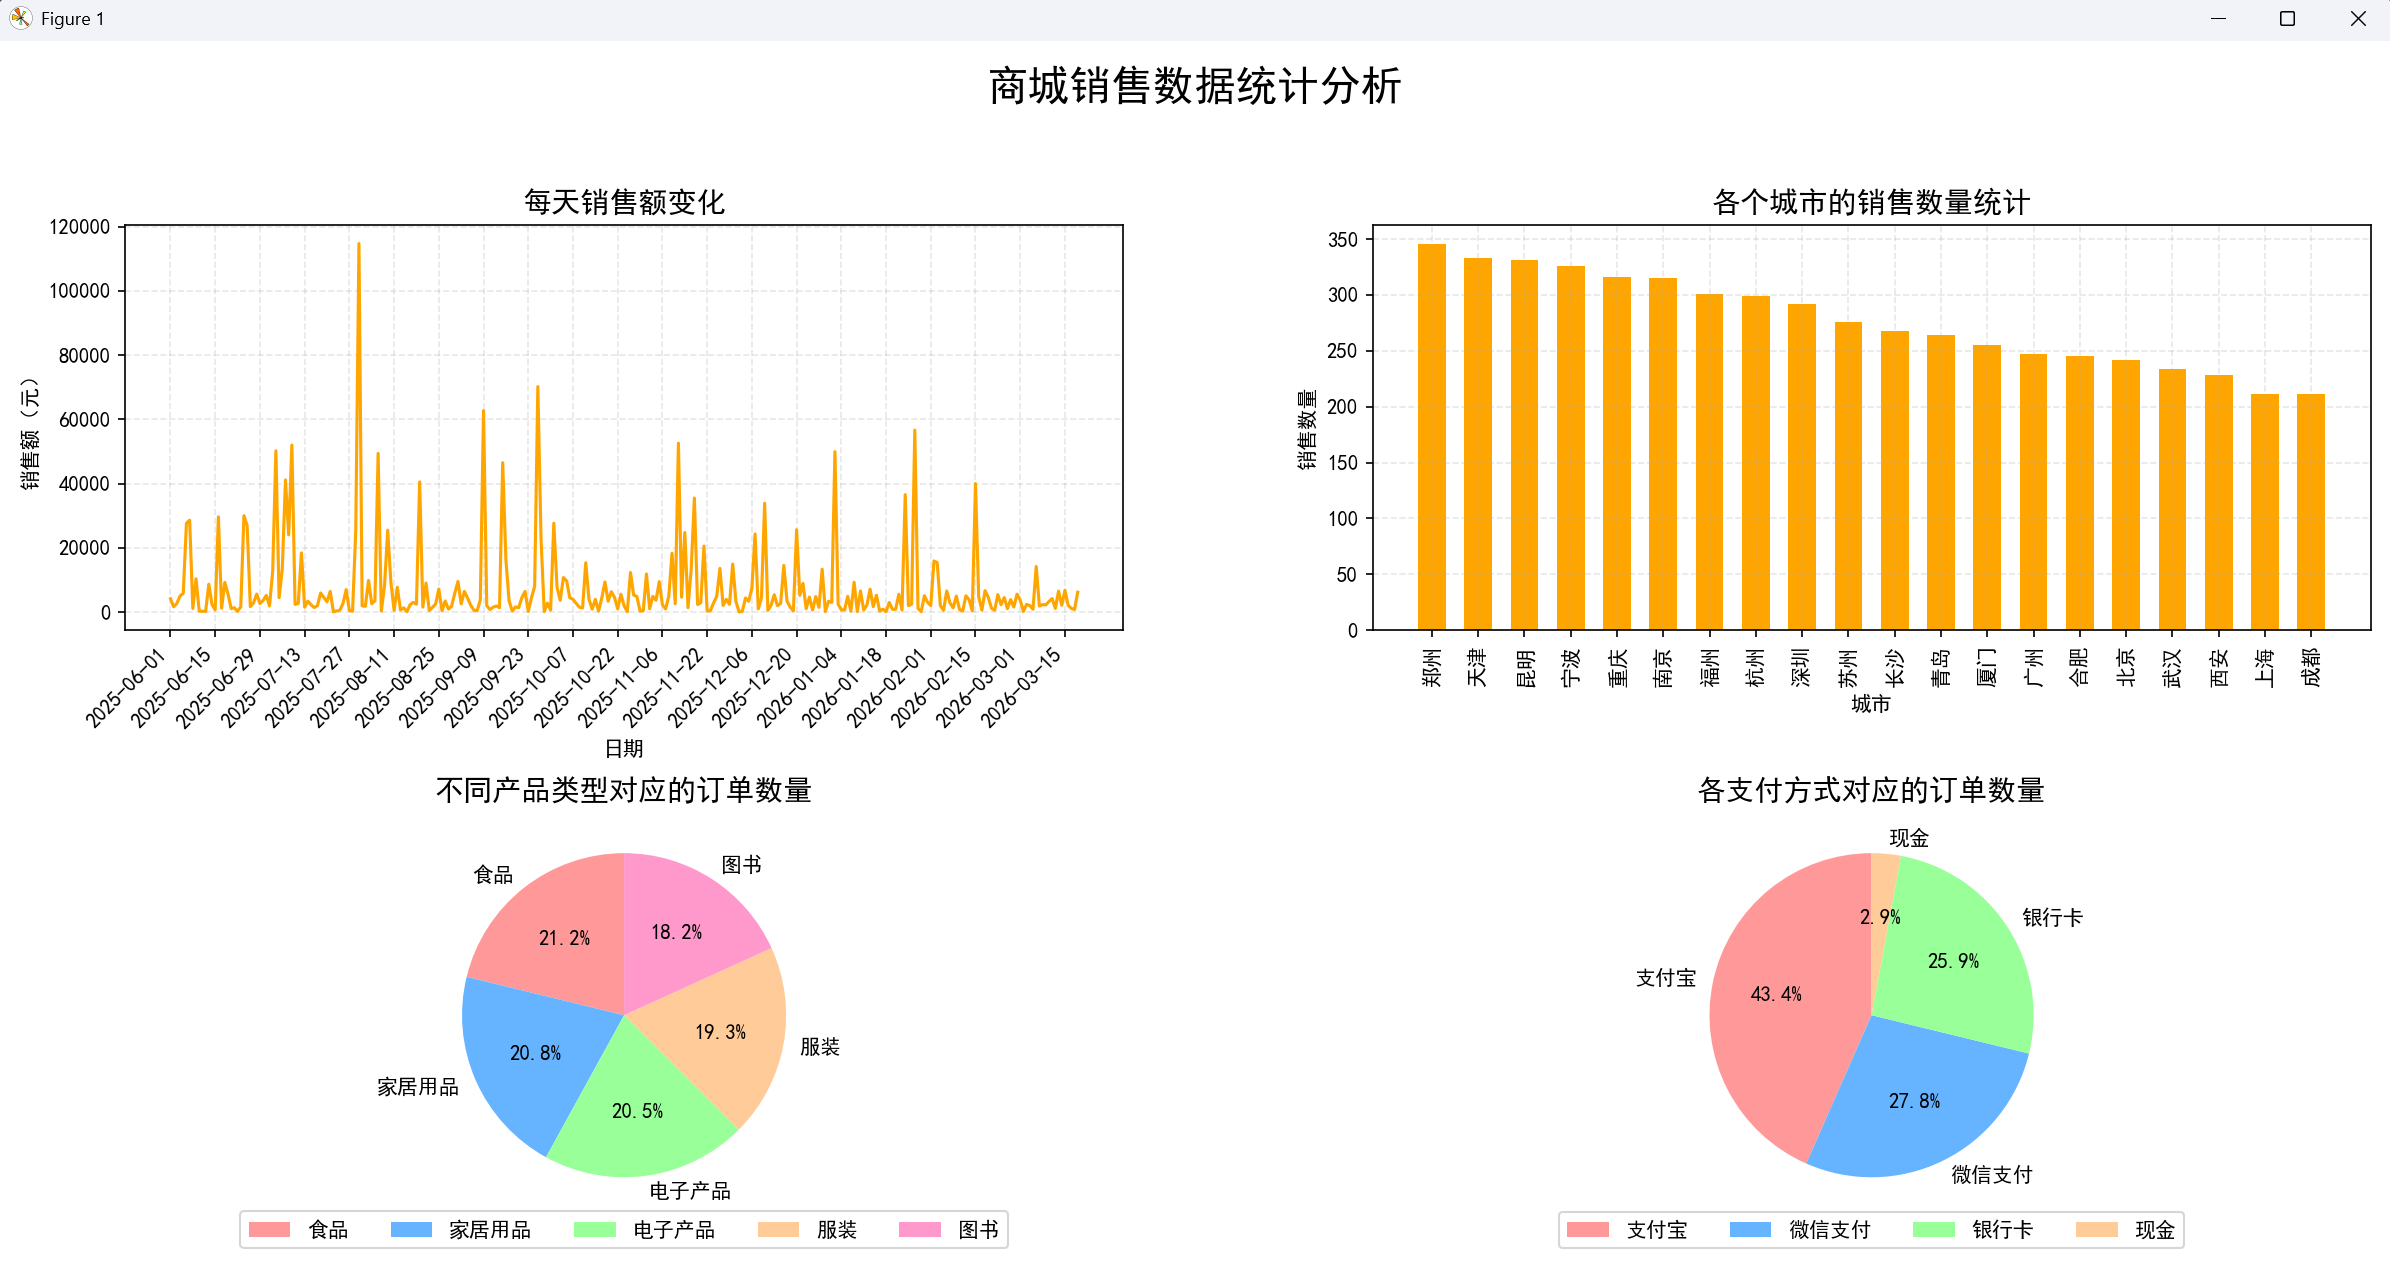

*讲义展示的销售分析效果：每日销售额、城市销售数量、类别订单比例、支付方式订单比例。它来自课件的完整数据，后文的小样本输出与之不同。*

## 二、环境准备与 Jupyter Notebook

### 1. Notebook 是什么

Jupyter Notebook 是基于 Web 界面的交互式编程工具。一个 `.ipynb` 文件可以同时保存代码、运行结果、图表和文字说明，常用于数据分析、机器学习与实验记录。

它仍然通过 Python 解释器执行 Python 代码。浏览器或 IDE 显示的是编辑界面，真正执行代码的是背后的 **内核（kernel）**。

| 对比项 | Python 文件 `.py` | Notebook 文件 `.ipynb` |
| --- | --- | --- |
| 组织方式 | 一份连续的程序文本 | 一组单元格 |
| 执行方式 | 通常从头运行，也可调试 | 可以逐格执行 |
| 结果 | 终端输出、窗口或文件 | 可直接显示在代码单元格下方 |
| 说明文字 | 注释、文档字符串 | Markdown 标题、段落、表格、公式等 |
| 适用场景 | 脚本、模块、应用程序 | 探索数据、分析记录、教学演示 |

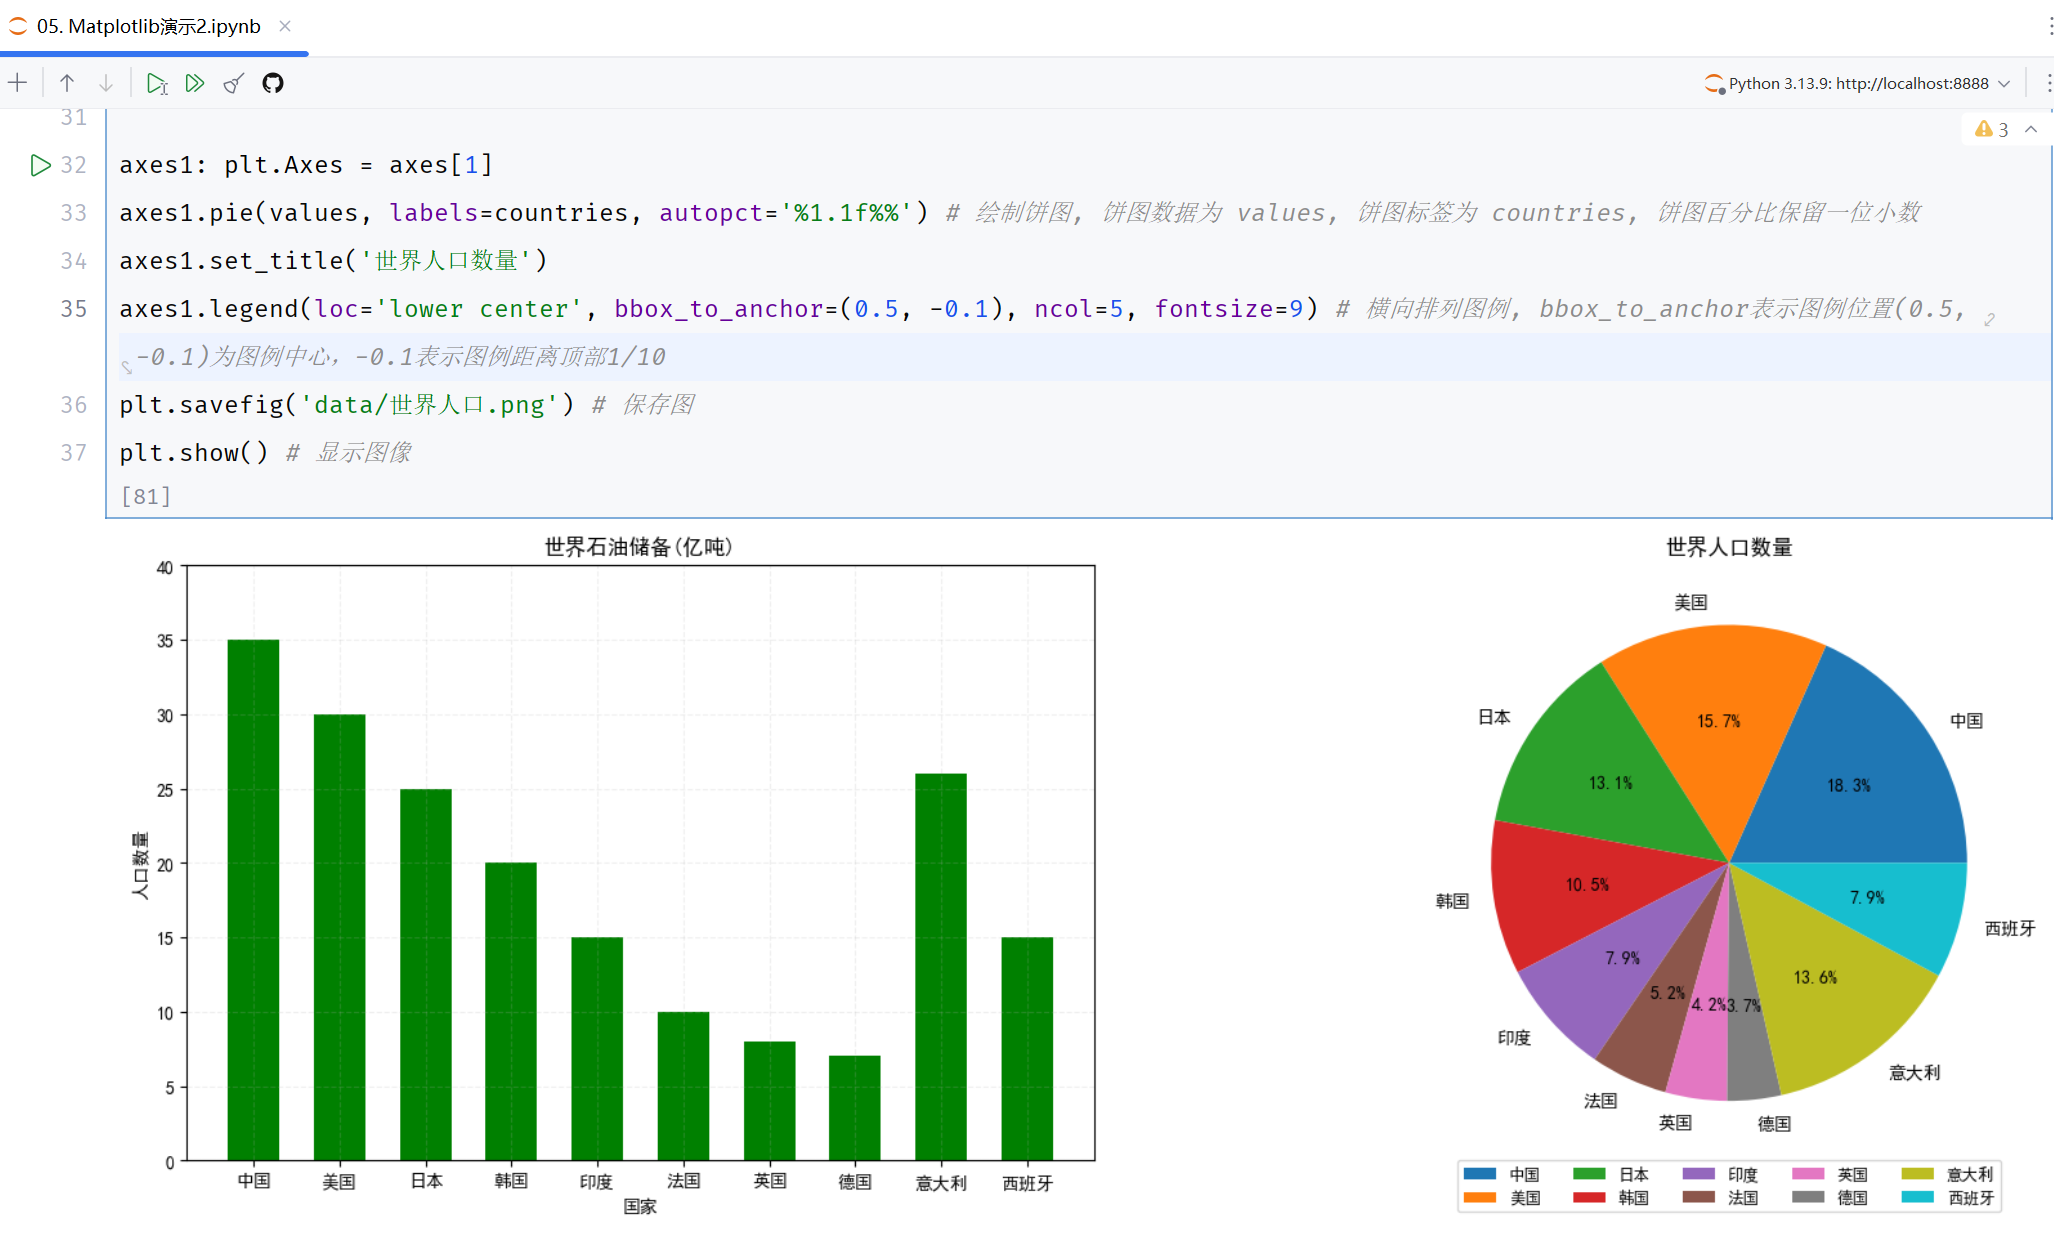

*课件中的 Notebook 界面：代码、柱状图与饼图保存在同一份文档中。*

课件还把前一章的正则表达式演示分别放进 `.py` 与 Notebook，说明相同的 Python 代码可以使用不同的组织和展示方式。

### 2. 在 PyCharm 中新建

讲义操作是在项目中右键，选择新建 Jupyter Notebook，再保存为 `.ipynb`。课件截图中的环境第一次使用时提示安装相关组件。

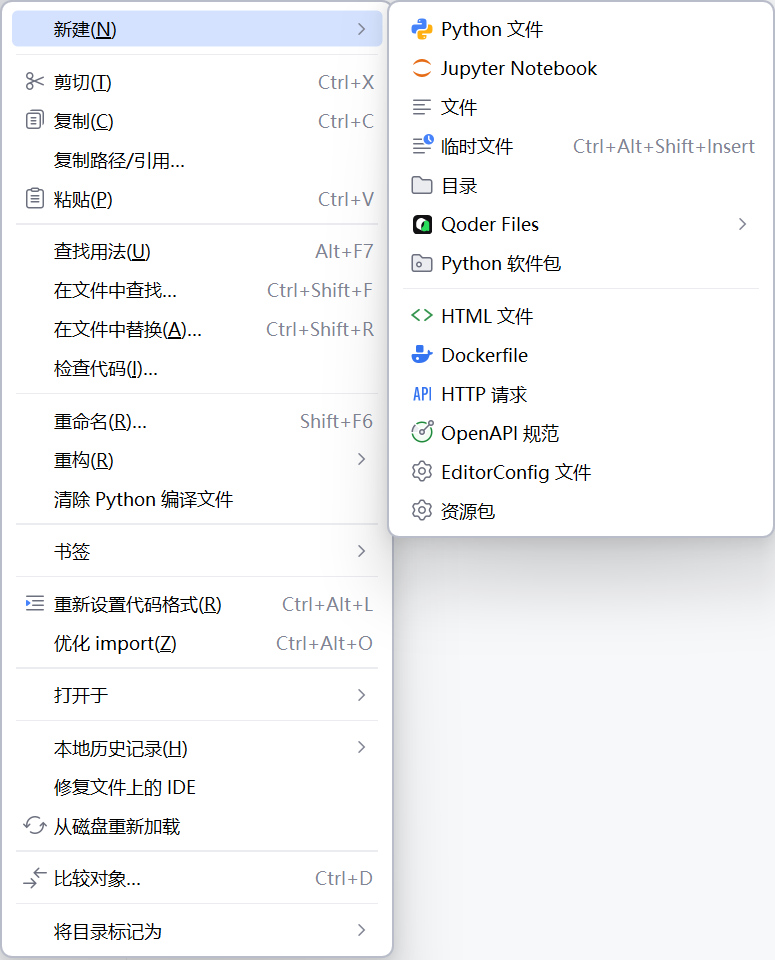

*课件中的 PyCharm 新建 Jupyter Notebook 菜单；实际菜单和功能支持会随 IDE 版本而变化。*

**补充：**自动安装是否出现，取决于 IDE 版本和环境配置。若没有相同入口，也可以直接使用浏览器版 Jupyter，不必为了菜单差异停在这一步。

在所选 Python 环境中安装本章依赖：

```powershell
python -m pip install notebook ipykernel pandas==2.3.3 matplotlib openpyxl
```

其中 Pandas 版本跟随讲义；`openpyxl` 用于本章的 `.xlsx` 读写。启动浏览器版：

```powershell
python -m notebook
```

如果项目使用虚拟环境，应先选择该解释器，再使用它安装依赖和启动 Notebook。遇到“终端装好了，Notebook 却提示找不到模块”，先核对内核是否使用同一个环境：

```python
import sys
import pandas as pd

print(sys.executable)
print(pd.__version__)
```

### 3. 运行时要记住的操作

**补充：Notebook 使用要点。**

1. **Code 单元格**执行 Python；**Markdown 单元格**保存说明文字。
2. 通常用 **Shift + Enter** 执行当前单元格并移到下一个。
3. 同一个内核中的单元格共享变量。前面创建了 `df`，后面才可以使用它。
4. 单元格的视觉顺序不一定等于已经执行的顺序。先运行下面、再修改上面，容易留下旧变量。
5. 完成一段分析后，可以“重启内核并按顺序运行所有代码”，确认结果不是依赖之前残留的状态。
6. 读取相对路径文件时，路径相对于内核的当前工作目录，先用 `Path.cwd()` 确认。

本节复习：Notebook 能保存哪些内容？代码、输出、图表和说明；它是否还需要 Python 解释器？需要；单元格中的变量为什么可以在后面继续使用？因为使用同一个内核。

## 三、Pandas 初体验：统计班级成绩

### 1. Pandas 与两种核心结构

Pandas 是常用的数据处理与分析库，建立在 NumPy 等基础之上，适合处理有行、有列、有字段含义的结构化数据。官网：[Pandas](https://pandas.pydata.org/)。

- **DataFrame：**二维表格，可以理解为一张有行、有列的 Excel 工作表。
- **Series：**一维、带索引标签的数据，可以独立创建，也经常是从 DataFrame 中取出的一列。

DataFrame 中不同列可以有不同类型，例如姓名列保存字符串，成绩列保存数值。行索引用来标识行，列名用来标识字段；索引不一定是 `0、1、2`，也不一定等于某个业务字段。

**勘误：**课件第 15 页把安装命令写成 `npm install pandas==2.3.3`。npm 是 JavaScript 生态的包管理工具，这里应使用：

```powershell
python -m pip install pandas==2.3.3
```

### 2. 讲义完整成绩案例

任务：统计班级学员语文、数学、英语三科的最高分、最低分和平均分。

```python
import pandas as pd

df1 = pd.DataFrame([
    {'姓名': '张三', '语文': 85, '数学': 92, '英语': 78},
    {'姓名': '李四', '语文': 78, '数学': 88, '英语': 95},
    {'姓名': '王五', '语文': 92, '数学': 96, '英语': 89},
    {'姓名': '赵六', '语文': 85, '数学': 90, '英语': 90},
    {'姓名': '孙七', '语文': 72, '数学': 59, '英语': 66},
    {'姓名': '周八', '语文': 80, '数学': 76, '英语': 68},
    {'姓名': '吴九', '语文': 85, '数学': 85, '英语': 85},
    {'姓名': '郑十', '语文': 57, '数学': 68, '英语': 49}
])
print(f"最高分: {df1['语文'].max()}, 最低分: {df1['语文'].min()}, 平均分: {df1['语文'].mean()}")
print(f"最高分: {df1['数学'].max()}, 最低分: {df1['数学'].min()}, 平均分: {df1['数学'].mean()}")
print(f"最高分: {df1['英语'].max()}, 最低分: {df1['英语'].min()}, 平均分: {df1['英语'].mean()}")
```

代码中外层列表的每个字典代表一个学生；字典的键成为列名；`df1['语文']` 取出语文这一列，再对这列调用统计方法。

| 方法 | 含义 |
| --- | --- |
| `max()` | 最大值，也就是该科最高分 |
| `min()` | 最小值，也就是该科最低分 |
| `mean()` | 算术平均值 |

用课件中的 8 位学生数据计算，结果为：

| 学科 | 最高分 | 最低分 | 平均分 |
| --- | ---: | ---: | ---: |
| 语文 | 92 | 57 | 79.25 |
| 数学 | 96 | 59 | 81.75 |
| 英语 | 95 | 49 | 77.50 |

`77.5` 与 `77.50` 的数值相同，差别只是显示格式。不要把整张表直接拿来求成绩平均值，因为姓名不是成绩字段。

**补充：缺失值与统计。**这些常见数值聚合默认会跳过缺失值。若某人成绩缺失，平均值的分母通常是有效成绩数，而不是班级总人数；缺考是否记零，需要根据成绩规则决定。

## 四、DataFrame 的构造与属性

### 1. 四种构造方式

下面是讲义的四种写法。此处使用 3 位学生演示结构，`df1` 会重新指向这份三行数据，不再是上一节的八人表。

先导入：

```python
import pandas as pd
```

```python
df1 = pd.DataFrame([
    {'姓名': '张三', '语文': 85, '数学': 92, '英语': 78},
    {'姓名': '李四', '语文': 78, '数学': 88, '英语': 95},
    {'姓名': '王五', '语文': 92, '数学': 96, '英语': 89}
])
df2 = pd.DataFrame({
    '姓名': ['张三', '李四', '王五'],
    '语文': [85, 78, 92],
    '数学': [92, 88, 96],
    '英语': [78, 95, 89]
})
df3 = pd.DataFrame([
    ('张三', 85, 92, 78),
    ('李四', 78, 88, 95),
    ('王五', 92, 96, 89)
], columns=['姓名', '语文', '数学', '英语'])
df4 = pd.DataFrame([
    ['张三', 85, 92, 78],
    ['李四', 78, 88, 95],
    ['王五', 92, 96, 89]
], columns=['姓名', '语文', '数学', '英语'], index=['a', 'b', 'c'])
```

| 对象 | 原始数据形式 | 怎样理解 |
| --- | --- | --- |
| `df1` | 列表中的字典 | 每个字典是一行，键是列名 |
| `df2` | 字典中的列表 | 每个键是一列，对应列表保存整列的值 |
| `df3` | 列表中的元组 | 每个元组是一行，用 `columns` 指定各位置的含义 |
| `df4` | 二维列表 | 每个内部列表是一行，另设列名和行索引 |

字典中的列表应具有相同长度；使用二维列表或元组时，每行数据应与 `columns` 的列数对应；`index` 的长度应与行数一致。

`df4` 的内容是：

| 索引 | 姓名 | 语文 | 数学 | 英语 |
| --- | --- | ---: | ---: | ---: |
| a | 张三 | 85 | 92 | 78 |
| b | 李四 | 78 | 88 | 95 |
| c | 王五 | 92 | 96 | 89 |

### 2. 常见属性

```python
print(df4.columns)
print(df4.index)
print(df4.values)
print(df4.dtypes)
print(df4.size)
print(df4.shape)
```

| 属性 | 作用 | 本例含义 |
| --- | --- | --- |
| `columns` | 列标签 | 姓名、语文、数学、英语 |
| `index` | 行标签 | a、b、c |
| `values` | 底层值组成的数组 | 三行四列的数据，不再携带行列标签 |
| `dtypes` | 每一列的数据类型 | 姓名通常是 object，成绩通常是整数类型 |
| `size` | 单元格总数 | `3 × 4 = 12` |
| `shape` | 形状，即行数与列数 | `(3, 4)` |

这些是**属性，不加括号**。`size` 统计的是所有数据位置，某个位置为空也算一个位置。混合类型 DataFrame 的 `values` 可能采用可容纳不同对象的类型；做分析时通常继续使用带有列名的 DataFrame 更直观。

## 五、Series 的构造与属性

### 1. 四种来源

讲义先后使用列表、元组、字典以及 DataFrame 中的列创建 Series：

```python
s = pd.Series([10, 20, 30, 40, 50])

s = pd.Series((10, 20, 30, 40, 50), index=['a', 'b', 'c', 'd', 'e'])

s = pd.Series({'a': 10, 'b': 20, 'c': 30, 'd': 40, 'e': 50})

s = df1['语文']

s = df1['数学']
```

这里反复给 `s` 赋值，是在展示不同方式，不是在把它们合并。需要保留多个结果时，可以分别命名为 `s1、s2、s3`。

对于 `pd.Series({'a': 10, 'b': 20})`，字典键成为索引标签，字典值成为数据。取出 `df1['数学']` 时，原 DataFrame 的行索引会保留。

### 2. Series 与 DataFrame 属性对照

| 属性 | DataFrame | Series |
| --- | --- | --- |
| 行标签 | `df.index` | `s.index` |
| 值 | `df.values` | `s.values` |
| 类型 | `df.dtypes`：每列一种类型 | `s.dtype`：这个 Series 的类型 |
| 大小 | `df.size`：行数 × 列数 | `s.size`：元素个数 |
| 形状 | `df.shape`：如 `(3, 4)` | `s.shape`：如 `(5,)` |
| 列标签 | `df.columns` | 没有 DataFrame 那样的一组列标签 |

```python
s = pd.Series([10, 20, 30, 40, 50], index=["a", "b", "c", "d", "e"])
print(s.index)
print(s.values)
print(s.dtype)
print(s.size)   # 5
print(s.shape)  # (5,)
```

`(5,)` 是只有一个元素的元组，表示一维长度为 5，不是五行一列的二维表。若需要二维的一列表格，应保留 DataFrame 形式。

**勘误：**课件小结把获取类型概括成 `xx.dtype`，需区分 Series 的单数 `dtype` 与 DataFrame 的复数 `dtypes`；形状也要区分一维与二维。第 18 页 Series 演示框上的“DataFrame”是沿用的标题。

本节复习：如何取列名？`df.columns`；如何看每列类型？`df.dtypes`；如何看一个 Series 的长度与形状？`s.size` 和 `s.shape`。

## 六、准备销售练习数据

**补充：让后面的读写、筛选和清洗可以直接练习。**

课件大量使用 `sales.csv`，但没有在 PPT 中附完整文件。以下代码按第 55 页截图前 10 行转写数据，保留缺失城市、负单价和日期格式差异，保存为 `sales_practice.csv`。它是有意保留问题的原始练习表。

新建一个学习目录，例如 `python-data-analysis`，把 Notebook 或脚本放在里面。后续约定的目录如下：

```text
python-data-analysis/
    chapter05.ipynb
    data/
        sales_practice.csv
        movies_practice.csv
    output/
        sales/
        movies/
```

先在该目录运行下面的准备代码。只有文件不存在时才创建，重新运行不会覆盖已经编辑过的数据。

```python
from pathlib import Path
import pandas as pd

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

# 补充练习素材：转写第 55 页截图的前 10 行，保留原图问题。
sales = pd.DataFrame([
    ("6805677496", "家居用品", "枕头", 10, 199, "合肥", "支付宝", "2025-06-01"),
    ("5857234132", "食品", "海苔", 5, 29, "天津", "现金", "2025-06-01"),
    ("5888085059", "电子产品", "智能音箱", 5, 399, "福州", "微信支付", "2025-06-01"),
    ("6823473137", "食品", "面包", 3, 29, "北京", "银行卡", "2025-06-02"),
    ("6801664364", "食品", "薯片", 2, 19, None, "微信支付", "2025/06/02"),
    ("5897064217", "图书", "字帖", 4, 29, "广州", "现金", "2025-06-02"),
    ("6857752388", "服装", "袜子", 7, -29, "郑州", "现金", "2025-06-02"),
    ("6898807429", "服装", "T恤", 6, 199, "武汉", "银行卡", "2025-06-02"),
    ("5875402232", "电子产品", "路由器", 9, 299, "福州", "银行卡", "2025-06-03"),
    ("5888085066", "图书", "字典", 2, 99, "青岛", "微信支付", "2025-06-04"),
], columns=["订单号", "产品类别", "产品名称", "销售数量", "单价",
            "客户所在城市", "支付方式", "订单日期"])

destination = data_dir / "sales_practice.csv"
if destination.exists():
    print("已有文件，保留原内容：", destination.resolve())
else:
    sales.to_csv(destination, index=False, encoding="utf-8-sig")
    print("已生成：", destination.resolve(), "行数：", len(sales))
```

订单号是标识符，不用于加减乘除，所以按字符串保存和读取。城市空白代表“缺失”，不能自行猜成其他城市。负单价会在清洗章节讨论。

**说明：**第 27 页清洗截图中，最后一行订单号与智能音箱重复；第 35、55 页同一位置是 `5888085066`。这里采用第 55 页编号，另在清洗章节演示如何识别第 27 页的重复键问题。

## 七、数据的读取与写入

### 1. read 与 to 的方向

Pandas 提供多种输入输出方法，可以与 CSV、Excel、数据库等数据来源配合。

| 操作 | 方法 | 结果 |
| --- | --- | --- |
| 读取 CSV | `pd.read_csv(...)` | 返回 DataFrame |
| 写入 CSV | `df.to_csv(...)` | 把表格保存到文件 |
| 读取 Excel | `pd.read_excel(...)` | 默认返回指定工作表的 DataFrame |
| 写入 Excel | `df.to_excel(...)` | 把表格写入工作簿 |

读取通常是 `pd.read_xxx`，写出通常是数据对象的 `to_xxx`。

### 2. 讲义中的读取、计算与导出

```python
import pandas as pd

df = pd.read_csv('../data/sales.csv', usecols=['订单日期', '产品类别', '销售数量', '单价', '客户所在城市', '支付方式'])
df['销售额'] = df['销售数量'] * df['单价']
df.head(20).to_csv('../data/sales_02.csv', index=False)
```

代码做了三件事：

1. 从 CSV 中只读取 `usecols` 指定的 6 个字段。
2. 按行计算“销售数量 × 单价”，新增“销售额”列。
3. 把前 20 行保存到新 CSV，`index=False` 表示不额外保存 DataFrame 的行索引。

`head(20)` 是前 20 行，不是抽样，也不是“前 20 个最大值”。如果只有 10 行，它就返回这 10 行。

### 3. 使用本笔记练习数据的对应写法

```python
from pathlib import Path
import pandas as pd

print("当前工作目录：", Path.cwd())
input_file = Path("data/sales_practice.csv")

df = pd.read_csv(
    input_file,
    usecols=["订单日期", "产品类别", "销售数量", "单价", "客户所在城市", "支付方式"],
    encoding="utf-8-sig",
)
df["销售额"] = df["销售数量"] * df["单价"]
df.head(20).to_csv("data/sales_02.csv", index=False, encoding="utf-8-sig")
```

**补充：路径与编码。**讲义的 `../data/sales.csv` 表示当前工作目录的上一层中的 data 目录；本笔记采用 `data/sales_practice.csv`，表示当前工作目录下的 data 目录。两种写法都可以，前提是与真实目录对应。Notebook 中通常不使用脚本专有的 `__file__` 来推断位置。

`encoding="utf-8-sig"` 常用于方便 Windows Excel 识别中文 CSV。它不能把 GBK 文件自动变成 UTF-8；真实文件要按其实际编码读取。`usecols` 中的名字要与表头完全对应，它不会自动把“产品分类”改为“产品类别”。

此时尚未清洗，负单价仍会产生负销售额。**能成功导出文件不代表数据已经正确**，正式分析要在清洗后重新计算销售额。

### 4. Excel 读写与缺少依赖

下面从完整销售表导出 Excel，再读回来：

```python
df = pd.read_csv(
    "data/sales_practice.csv",
    dtype={"订单号": "string"},
    encoding="utf-8-sig",
)
df.to_excel(
    "data/sales_practice.xlsx", sheet_name="销售明细",
    index=False, engine="openpyxl",
)
excel_df = pd.read_excel(
    "data/sales_practice.xlsx", sheet_name="销售明细",
    dtype={"订单号": "string"}, engine="openpyxl",
)
print(excel_df.head())
```

课件第 22 页展示了 `ModuleNotFoundError: No module named 'openpyxl'`。它表示当前环境缺少读取该 Excel 格式所需的库，应在 Notebook 内核所用的环境安装：

```powershell
python -m pip install openpyxl
```

`sheet_name` 指定工作表名称；`index=False` 只是不导出 DataFrame 的索引，不会删掉真实存在的“订单号”列。

## 八、查看数据、选择行列与条件过滤

### 1. 先查看，再计算

下面重新读取完整销售表，后续本节的 `df` 都指这份 10 行原始练习数据：

```python
import pandas as pd

df = pd.read_csv(
    "data/sales_practice.csv",
    dtype={"订单号": "string"},
    encoding="utf-8-sig",
)
print(df.head())
print(df.tail(3))
print(df.describe())
df.info()
print(df.shape)
print(df.columns)
```

| 写法 | 用途 | 注意点 |
| --- | --- | --- |
| `head(n)` | 查看前 n 行 | 默认 5 行 |
| `tail(n)` | 查看末尾 n 行 | 默认 5 行 |
| `describe()` | 查看数值列的统计描述 | 默认通常不把文本列按数值统计 |
| `info()` | 查看列名、非空数量、类型等 | 直接打印信息，返回值是 None |
| `shape` | 查看行数和列数 | 属性，不加括号 |
| `columns` | 查看列名 | 属性，不加括号 |

`describe()` 中常见行包括：

| 项目 | 含义 |
| --- | --- |
| count | 有效的非空值数量 |
| mean | 平均值 |
| std | 标准差，反映数值的离散程度 |
| min / max | 最小值 / 最大值 |
| 25% / 50% / 75% | 四分位数，50% 对应中位数 |

这里看 `min` 就能发现单价中出现了 `-29`；看 `info()` 能发现“客户所在城市”只有 9 个非空值。`print(df.info())` 会在信息后额外打印一个 `None`，通常直接写 `df.info()` 即可。

### 2. 选择列

```python
quantity = df["销售数量"]                    # Series
quantity_table = df[["销售数量"]]            # 一列的 DataFrame
selected = df[["产品名称", "销售数量", "单价"]]  # 三列的 DataFrame
print(quantity)
print(selected)
```

一层方括号里是一个列名，通常得到 Series；外层方括号里再放一个列名列表，得到 DataFrame。

课件还给出 `df.列名`。例如 `df.销售数量` 在此例中可以使用，但遇到空格、特殊字符、与对象属性重名的列名时不可靠，笔记统一优先使用 `df["列名"]`。

### 3. 选择行：iloc 与 loc

| 方法 | 根据什么选择 | 切片终点 |
| --- | --- | --- |
| `iloc` | 从 0 开始的整数位置 | 不包含 stop |
| `loc` | 索引标签 | 标签切片通常包含 stop 标签 |

```python
print(df.iloc[0:3])     # 位置 0、1、2
print(df.iloc[0:6:2])   # 位置 0、2、4
print(df.loc[0:3])      # 本例默认整数索引下，标签 0、1、2、3

demo = pd.DataFrame({"数值": [10, 20, 30]}, index=["a", "b", "c"])
print(demo.iloc[0:2])   # a、b 两行
print(demo.loc["a":"c"])  # a、b、c 三行
```

整数索引恰好等于行位置时，两者看起来很像；筛选、排序或自定义索引之后就不一定相同。例如排序后的索引 `7` 仍是标签 7，不等于当前第 8 行。

**补充：**`loc` 的标签范围切片受索引顺序和唯一性影响。初学示例采用明确、有序的索引；不要把 `loc` 当作“按第几行”的替代品。

### 4. 单条件过滤

`df[条件表达式]` 的条件应产生与行对应的一列布尔值：True 保留，False 排除。

```python
mask = df["销售数量"] >= 10
print(mask)
print(df[mask])

print(df[df["产品类别"].isin(["服装", "食品"])])
print(df[df["单价"].between(50, 200)])
print(df[df["单价"] >= 100])
```

`isin` 判断值是否属于给定集合；`between(50, 200)` 默认包含两个边界，即 `50 <= 单价 <= 200`。

**勘误：**课件的 `df[df['销售数量' >= 10]]` 把比较运算放进了列名括号，应改成 `df[df['销售数量'] >= 10]`。先取得这一列，再让整列与 10 比较。

### 5. 多条件过滤

| 运算符 | 含义 |
| --- | --- |
| `&` | 两个条件同时成立 |
| <code>&#124;</code> | 至少一个条件成立 |
| `~` | 条件取反，属于补充用法 |

```python
# 食品，并且销售数量至少为 3
food_orders = df[(df["产品类别"] == "食品") & (df["销售数量"] >= 3)]

# 服装，或者单价至少为 300
selected = df[(df["产品类别"] == "服装") | (df["单价"] >= 300)]

# 不属于食品类别
non_food = df[~df["产品类别"].isin(["食品"])]
print(food_orders)
print(selected)
print(non_food)
```

每个比较条件分别加括号，避免运算优先级产生错误。这里操作的是整列布尔值，不能直接用 Python 标量逻辑里的 `and`、`or`。

本节复习：查看前后几行用 `head/tail`；取单列与多列注意返回结构；位置切片用 `iloc`、标签切片用 `loc`；条件过滤把完整条件放在外层方括号中。

## 九、数据清洗：缺失、重复、异常与格式

### 1. 清洗要解决什么问题

数据清洗是发现并纠正数据中可识别错误的过程，包括处理缺失值、重复值、异常值，统一数据格式，保证数据的一致性。

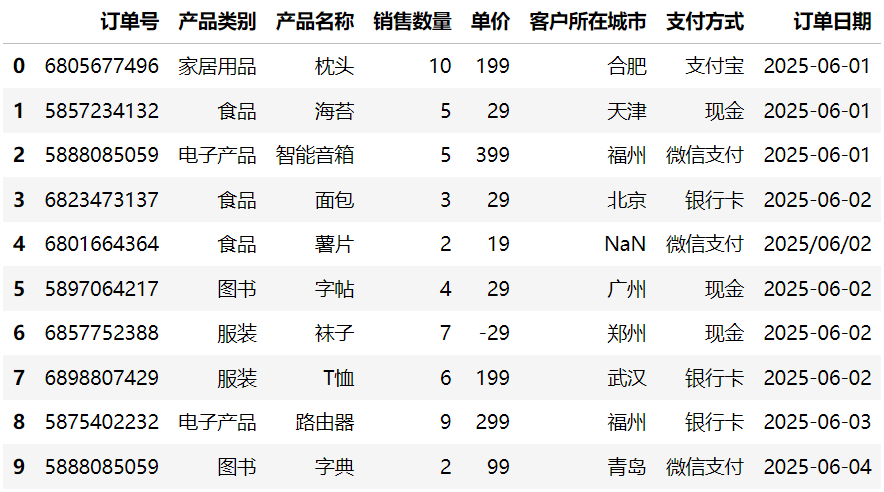

*讲义第 27 页的清洗示例：重复订单号、缺失城市、负单价，以及混用斜杠和连字符的日期。*

图中需要关注四处：

| 问题 | 截图现象 | 应先确认的事情 |
| --- | --- | --- |
| 重复键 | 智能音箱与字典的订单号相同 | 是同订单的不同明细，还是订单号录错 |
| 缺失值 | 薯片这一行没有城市 | 是否能从原始订单查回；不能凭相邻行猜城市 |
| 异常值 | 袜子单价为 -29 | 是录入错误，还是退货、冲销等业务记录 |
| 格式不统一 | `2025/06/02` 与 `2025-06-02` 并存 | 统一解析为日期后再排序、分组 |

下面先认识 API，再把它们组合成可执行的清洗流程。

### 2. 缺失值：检查、删除与填充

先重新加载原始练习表：

```python
import pandas as pd

df = pd.read_csv(
    "data/sales_practice.csv",
    dtype={"订单号": "string"},
    encoding="utf-8-sig",
)

print(df.isnull())                      # 与原表同形状的布尔表
print(df.isnull().sum())                # 每列缺失数量
print(df[df["客户所在城市"].isnull()])   # 城市缺失的记录
```

`isnull()` 与 `isna()` 都用于判断缺失。字符串 `"NaN"`、空格、`"<null>"` 是否成为缺失值，取决于读取参数与转换方式；不能只凭界面显示判断。

| 方法 | 作用 | 用在什么情形 |
| --- | --- | --- |
| `dropna()` | 删除含缺失值的行，默认检查所有列 | 缺失使该条数据无法用于当前分析时 |
| `dropna(subset=[...])` | 只按指定字段判断是否删除 | 只要求当前分析必须用到的字段有效 |
| `fillna(值)` | 用指定内容填充缺失 | 有业务依据，或用“未知”保留分类信息 |
| `ffill()` | 用前面最近的非空值向后填 | 数据的顺序与业务含义支持沿用上一个值时 |
| `bfill()` | 用后面最近的非空值向前填 | 业务含义允许用后一个值回填时 |

```python
# 对照不同做法，暂时分别保存结果
drop_all_missing = df.dropna()
drop_missing_city = df.dropna(subset=["客户所在城市"])
filled_city = df.fillna({"客户所在城市": "未知"})

print(len(df))                # 10
print(len(drop_all_missing))  # 9
print(len(filled_city))       # 10
```

此例中缺失城市不影响计算那笔订单的销售额。若直接 `dropna()`，会连它的销售额也一起丢掉。因此分析销售总额时可保留该行，城市分类中单列“未知”。

前向和后向填充的独立示例：

```python
s = pd.Series([None, 10, None, 20, None])
print(s.ffill().tolist())  # [nan, 10.0, 10.0, 20.0, 20.0]
print(s.bfill().tolist())  # [10.0, 10.0, 20.0, 20.0, nan]
```

首部没有前值，`ffill` 不能填；末尾没有后值，`bfill` 不能填。它们不是根据数学规律推算中间值，也不会自动插值。

**补充：**若数据属于多位客户、多台设备，应先按各自的组与时间排序，再判断能否组内填充。不能把上一位客户的城市填给下一位客户。

### 3. 重复值：先分清整行重复与业务键重复

```python
print(df.duplicated())  # 默认比较整行，首次出现为 False，后续相同行为 True
unique_rows = df.drop_duplicates()

# 人为追加同一行，演示整行去重
repeated = pd.concat([df, df.iloc[[0]]], ignore_index=True)
print(len(repeated))                   # 11
print(len(repeated.drop_duplicates())) # 10
```

`duplicated()` 负责标记，`drop_duplicates()` 负责返回去重后的数据。默认保留第一次出现的记录；`keep="last"` 保留最后一次；`keep=False` 可把所有重复项都标出来，方便检查。

**补充：复现第 27 页的订单号问题。**

```python
problem = df.copy()
problem.loc[9, "订单号"] = problem.loc[2, "订单号"]
conflicts = problem[
    problem.duplicated(subset=["订单号"], keep=False)
]
print(conflicts[["订单号", "产品名称", "销售数量", "单价"]])
```

这会找到订单号同为 `5888085059` 的智能音箱和字典。它们的商品、数量、单价不同，**不是整行重复**，不能不加判断就按订单号删掉后一行。

- 如果一行代表一张完整订单，重复订单号需要回到原始记录核对。
- 如果一行代表一条商品明细，同订单号出现多行可能完全正常。
- 只有已经确认“哪几列能唯一标识一条重复业务记录”时，才适合设置 `subset` 去重。

课件后面的截图将字典订单号写为 `5888085066`，本笔记的小样本采用这个编号，不通过删除商品的方式解决冲突。

### 4. 异常值：abs 的用法与前提

`abs()` 返回绝对值。讲义给出的写法是：

```python
example = pd.DataFrame({"单价": [199, -29, 99]})
example["单价"] = example["单价"].abs()
print(example["单价"].tolist())  # [199, 29, 99]
```

它展示了数值变换，但**不代表所有负数都应转成正数**。退货数量、退款金额、温度、盈亏等字段中的负值可能本来就是正确的。

本章样例的袜子单价在清洗截图中为 `-29`，在第 35 页分组表中为 `29`。为了衔接课件练习，下面明确按“该样例单价误录”处理；真实文件需要另行核实。

### 5. 日期与字符串格式

讲义使用 `str.replace('/', '-')` 统一日期分隔符。完整赋值写法：

```python
df["订单日期"] = df["订单日期"].str.replace("/", "-", regex=False)
print(df["订单日期"].head())
```

`str` 是 Pandas 提供的字符串操作入口，会把相应字符串方法应用到整列。此处 `regex=False` 表示按普通文本替换。

仅替换分隔符后，值仍可能是字符串。**补充：**正式按日统计之前，应转成日期类型：

```python
df["订单日期"] = pd.to_datetime(
    df["订单日期"], format="%Y-%m-%d", errors="coerce"
)
print(df["订单日期"].dtype)
print(df[df["订单日期"].isna()])
```

无法解析的日期会变成 `NaT`，应检查这些行，不能默认它们发生在某个日期。如果原始字符串有多种已确认的日期格式，Pandas 2.3.3 也可以使用 `format="mixed"`；含义模糊的月日顺序仍须按数据来源明确。

**补充：数值转换。**

```python
numbers = pd.Series(["10", "20", "录入错误", None])
converted = pd.to_numeric(numbers, errors="coerce")
print(converted)
```

结果中前两个值成为数值，后两个为缺失。`errors="coerce"` 使程序能标记问题继续检查，不表示错误已经被修复；不要紧接着把所有缺失填成零。

### 6. 把清洗步骤串起来

以下是针对本笔记 10 行样例的补充参考代码。运行后得到的 `df` 将用于排序和分组章节。

```python
import pandas as pd

raw = pd.read_csv(
    "data/sales_practice.csv",
    dtype={"订单号": "string"},
    encoding="utf-8-sig",
)
df = raw.drop_duplicates().copy()
df["客户所在城市"] = df["客户所在城市"].fillna("未知")

for column in ["销售数量", "单价"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["订单日期"] = pd.to_datetime(
    df["订单日期"], format="mixed", errors="coerce"
)

# 按课件第 35 页，仅修正这个明确的教学样例
fix = (
    df["订单号"].eq("6857752388")
    & df["产品名称"].eq("袜子")
    & df["单价"].eq(-29)
)
df.loc[fix, "单价"] = df.loc[fix, "单价"].abs()

invalid = (
    df[["订单日期", "销售数量", "单价"]].isna().any(axis=1)
    | (df["销售数量"] <= 0)
    | (df["单价"] < 0)
)
if invalid.any():
    print(df.loc[invalid])
    raise ValueError("存在待核查记录，先核实后再统计。")

df["销售额"] = df["销售数量"] * df["单价"]
print(df[["订单号", "产品名称", "销售数量", "单价", "销售额"]])
```

`copy()` 让后续修改针对独立的数据对象；`df.loc[条件, "列名"] = 新值` 是明确选择行列再赋值的写法，避免在临时筛选结果上做含糊的连锁赋值。

清洗后仍有 10 行，城市缺失处为“未知”，袜子单价为 29，销售总量为 **53 件**，销售总额为 **8657 元**。最后重新计算“销售额”，保证使用修正后的单价。

本节复习：

| 问题 | 答案 |
| --- | --- |
| `isnull` 做什么 | 找出缺失位置，不直接修改数据 |
| `dropna` 与 `fillna` 的区别 | 前者删除，后者填值 |
| `ffill` 与 `bfill` 的区别 | 分别使用前面的、后面的非空值 |
| `duplicated` 与 `drop_duplicates` 的区别 | 前者标记，后者返回去重结果 |
| `abs` 能否无条件清理异常值 | 不能，要先确认负号确实是错误 |
| `str.replace` 后为什么还要转日期 | 字符串格式统一不等于已经获得日期类型 |

## 十、数据排序

### 1. 单列排序

在上一节清洗后的 `df` 上运行：

```python
ascending_df = df.sort_values("销售数量", ascending=True)
descending_df = df.sort_values("销售数量", ascending=False)
print(ascending_df[["产品名称", "销售数量"]])
print(descending_df[["产品名称", "销售数量"]])
```

`ascending=True` 表示从小到大；`False` 表示从大到小。不写时默认升序。

`sort_values` 默认返回排好序的新对象，原来的 `df` 不会自动变成新顺序。需要保留时应赋值，例如 `df = df.sort_values(...)`。

### 2. 多列排序

```python
sorted_df = df.sort_values(
    ["销售数量", "单价"],
    ascending=[True, True],
)
print(sorted_df[["产品名称", "销售数量", "单价"]])
```

先按销售数量升序；数量相同，才比较单价。它不是把每一列脱离所在行分别排序，整行记录始终一起移动。

本例数量都为 2 的薯片、字典，会先按单价 19、99 排列；数量都为 5 的海苔、智能音箱，会按 29、399 排列。

### 3. 讲义练习与答案

```python
result1 = df.sort_values("销售数量", ascending=False)

result2 = df.sort_values(
    ["销售数量", "订单日期"],
    ascending=[True, False],
)

result3 = df.sort_values(
    ["销售数量", "订单日期"],
    ascending=False,
)
```

| 结果 | 含义 |
| --- | --- |
| result1 | 销售数量降序 |
| result2 | 数量升序；数量相同时，日期降序 |
| result3 | 数量降序；数量相同时，日期也降序 |

`ascending` 为列表时，与排序列一一对应；为单个布尔值时，对所有排序列使用相同方向。日期已在上节转成日期类型，按日期先后排序更可靠。

**补充：**排序后默认保留原来的索引标签。如需按新顺序重新编号，可以使用 `sorted_df.reset_index(drop=True)`；这只是重建行索引，不是修改订单号。

## 十一、数据分组与聚合

### 1. groupby 的思路

分组就是按某个特征把记录分成不同组，再对每一组进行统计。

课件先展示一堆混在一起的图标，然后按照颜色分组：黑色一组、红色一组。换成数据，“产品类别”列就是分组依据，同为食品的记录进入食品组，同为服装的进入服装组。

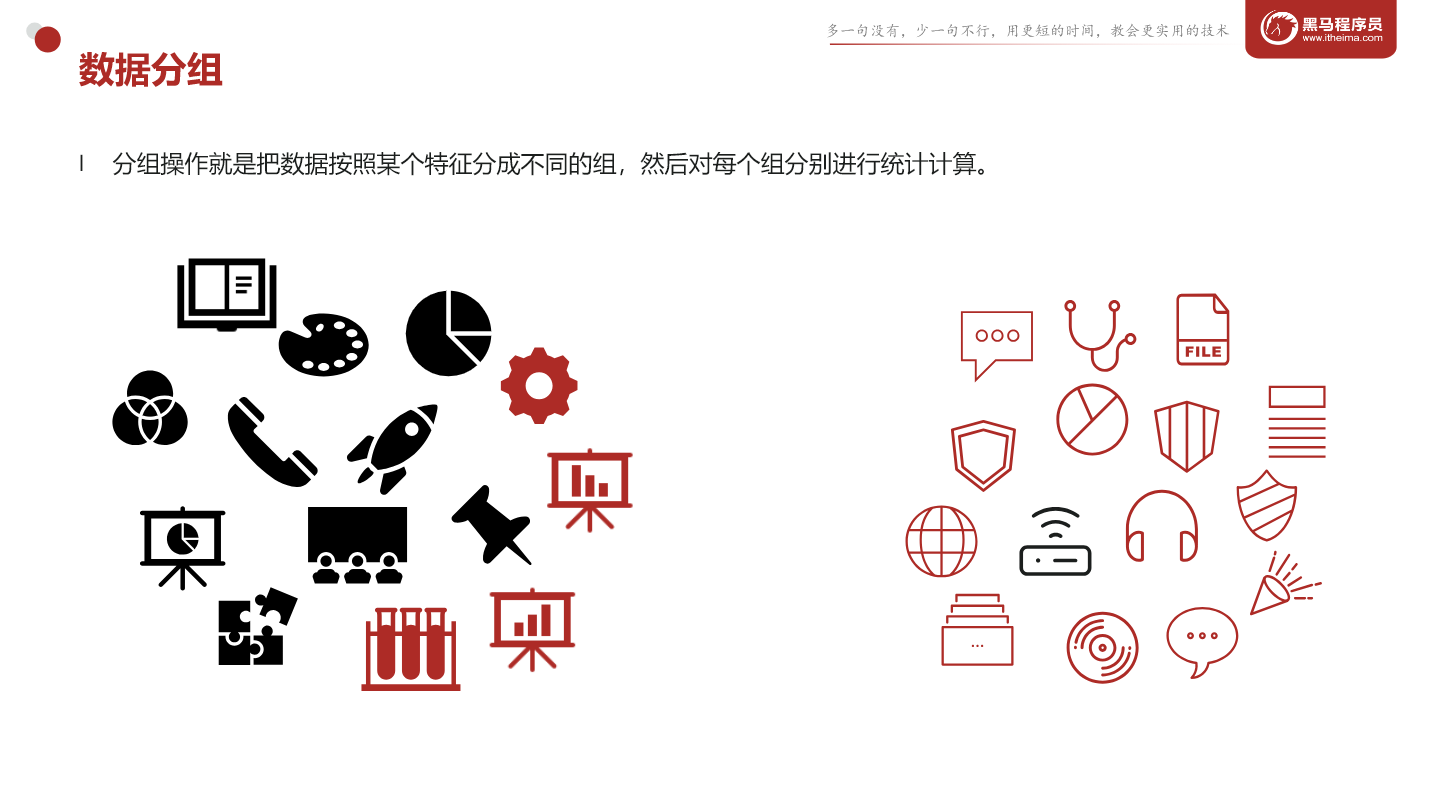

*讲义的分组示意：先明确分类依据，再对每个组单独处理。*

完整思路可以写成：

```text
原始表 → 按产品类别拆成多组 → 每组选择销售额 → 分别统计 → 合并为结果表
```

### 2. 讲义中的销售数据

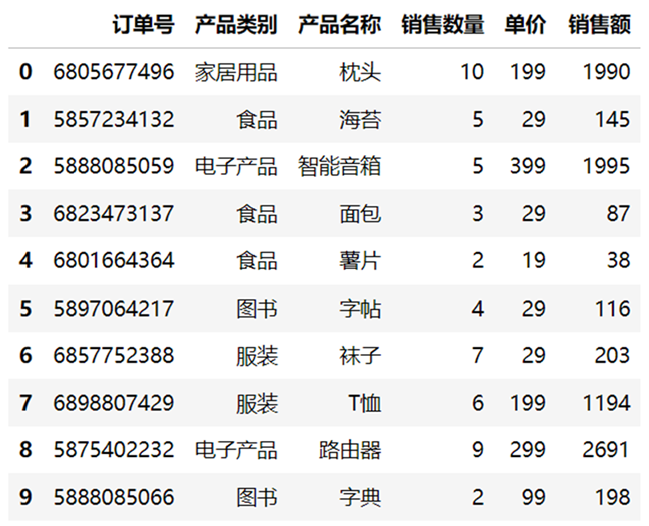

*讲义第 35 页的十行销售数据。其单价与销售额对应清洗后的示例。*

数据中的“销售额”是每一行的金额。例如枕头 `10 × 199 = 1990` 元；电子产品组含智能音箱与路由器，其销售额合计为 `1995 + 2691 = 4686` 元。

### 3. 常用聚合方法

```python
grouped = df.groupby("产品类别")["销售额"]
print(grouped.sum())
print(grouped.count())
print(grouped.max())
print(grouped.min())
print(grouped.mean())
```

| 方法 | 本例含义 | 食品组结果 |
| --- | --- | ---: |
| `sum()` | 该类别销售额总和 | 270 |
| `count()` | 该类别销售额非空记录数 | 3 |
| `max()` | 该类别单行销售额最大值 | 145 |
| `min()` | 该类别单行销售额最小值 | 38 |
| `mean()` | 该类别有效单行销售额的平均值 | 90 |

`mean` 在这里表示每条记录的平均销售额，不是平均单价，也不是所有商品的加权平均售价。

### 4. 一次聚合多项指标

```python
summary = df.groupby("产品类别")["销售额"].agg(
    ["sum", "count", "max", "min", "mean"]
)
print(summary)
```

十行清洗样例的结果：

| 产品类别 | sum | count | max | min | mean |
| --- | ---: | ---: | ---: | ---: | ---: |
| 图书 | 314 | 2 | 198 | 116 | 157 |
| 家居用品 | 1990 | 1 | 1990 | 1990 | 1990 |
| 服装 | 1397 | 2 | 1194 | 203 | 698.5 |
| 电子产品 | 4686 | 2 | 2691 | 1995 | 2343 |
| 食品 | 270 | 3 | 145 | 38 | 90 |

合计 `314 + 1990 + 1397 + 4686 + 270 = 8657`，应与原表清洗后的销售额总和一致。

还可以只选需要的函数：

```python
print(df.groupby("产品类别")["销售额"].agg(["sum", "max", "min"]))
```

### 5. 不同列使用不同的函数

```python
summary = df.groupby("产品类别").agg({
    "销售数量": "sum",
    "销售额": "sum",
    "单价": "mean",
})
print(summary)
```

字典键表示要处理的列，值表示该列使用的聚合函数。此例对数量和金额求和，对每条记录的单价取算术平均。

**勘误：**课件第 36 页写成 `agg(['销售数量':'sum', ...])`，冒号键值对应应放在字典大括号 `{}` 中，不能放在列表中；该处的“销售金额”与前面的“销售额”也不一致，笔记统一使用“销售额”。

**补充：**若要算按销售数量加权的实际平均售价，应使用 `销售额总和 / 销售数量总和`，它与 `单价.mean()` 不是同一指标。例如卖了 1 件 100 元商品、9 件 10 元商品时，按记录算单价平均为 55 元，按件数加权则为 19 元。

### 6. count、size 与 nunique 不要混淆

```python
small = pd.DataFrame({
    "类别": ["食品", "食品", "食品"],
    "订单号": ["A001", "A001", "A002"],
    "销售额": [10, None, 20],
})
print(small.groupby("类别")["销售额"].count())  # 2 个有效销售额
print(small.groupby("类别").size())            # 3 行
print(small.groupby("类别")["订单号"].nunique()) # 2 个不同订单号
```

这是理解案例所必需的补充：

- `count` 数指定列的非空值。
- `size` 数分组中的行数。
- `nunique` 数不同值的个数，默认不计缺失。
- `sum` 把数值相加，统计售出件数时应该对“销售数量”求和。

当“每行一个独立订单，订单号与金额都没有缺失”时，几种计数可能恰好一样；这并不意味着它们的定义相同。

**补充：分组键缺失。**`groupby` 默认可能排除分组键为空的记录。本章提前把缺失城市填为“未知”，使这两件商品仍能进入城市统计；也可按需要使用 `dropna=False` 显式保留空键组。

### 7. 从统计表转成图

课件用“一图胜千言”展示：前面得到的类别与支付方式统计，可以继续转为饼图。作图之前必须确定比例的分母是订单数、件数还是金额。

课件不同页面使用的展示数据范围不完全一样。第 35 页的十行明细与第 37 页的较大汇总表，不应硬算成同一份数据；笔记的可复现结果都以已给出的十行样例为准。下面保留课件这一页的两张汇总表，方便对照“数量求和、金额求和、单价求平均”与“订单计数”的结果形式：

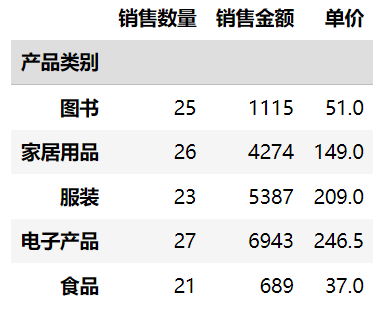

*课件第 37 页按产品类别汇总：数量求和、金额求和、单价求平均；数据范围大于前面的十行示例。*

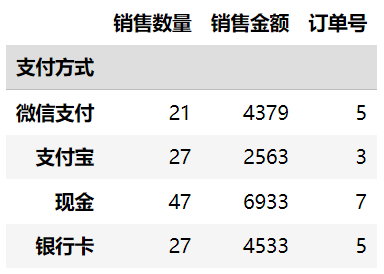

*课件第 37 页按支付方式汇总：最后一列展示订单计数；不要把它当成销售数量。*

本节复习：分组列决定“按什么分类”，被选择的列决定“统计什么”，聚合函数决定“怎样计算”。这三个问题回答清楚，`groupby` 的写法就有了依据。

## 十二、Matplotlib 初识

### 1. 安装与最小折线图

Matplotlib 是 Python 常用的数据可视化库，可以绘制静态图、动画和交互图。本章使用 `pyplot` 绘制折线图、柱状图和饼图。官网：[Matplotlib](https://matplotlib.org/)。

```powershell
python -m pip install matplotlib
```

讲义入门代码：

```python
import matplotlib.pyplot as plt

x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
y = [6, 2, 9, 8, 10, 1, 5, 4, 3, 7]

plt.plot(x, y)
plt.show()
```

`import matplotlib.pyplot as plt` 给绘图模块起一个简短别名。`plt.plot(x, y)` 按顺序连接数据点；`plt.show()` 显示图形。

这组数据有 10 个 x 值和 10 个 y 值，第一点为 `(1, 6)`，第二点为 `(2, 2)`。**x 和 y 的长度必须一致**，否则每个点无法组成坐标对。

折线图按传入顺序连接点。分析日期变化时，必须先把日期排序，不能指望绘图库替你自动整理数据的业务顺序。

### 2. 读懂一张图的组成

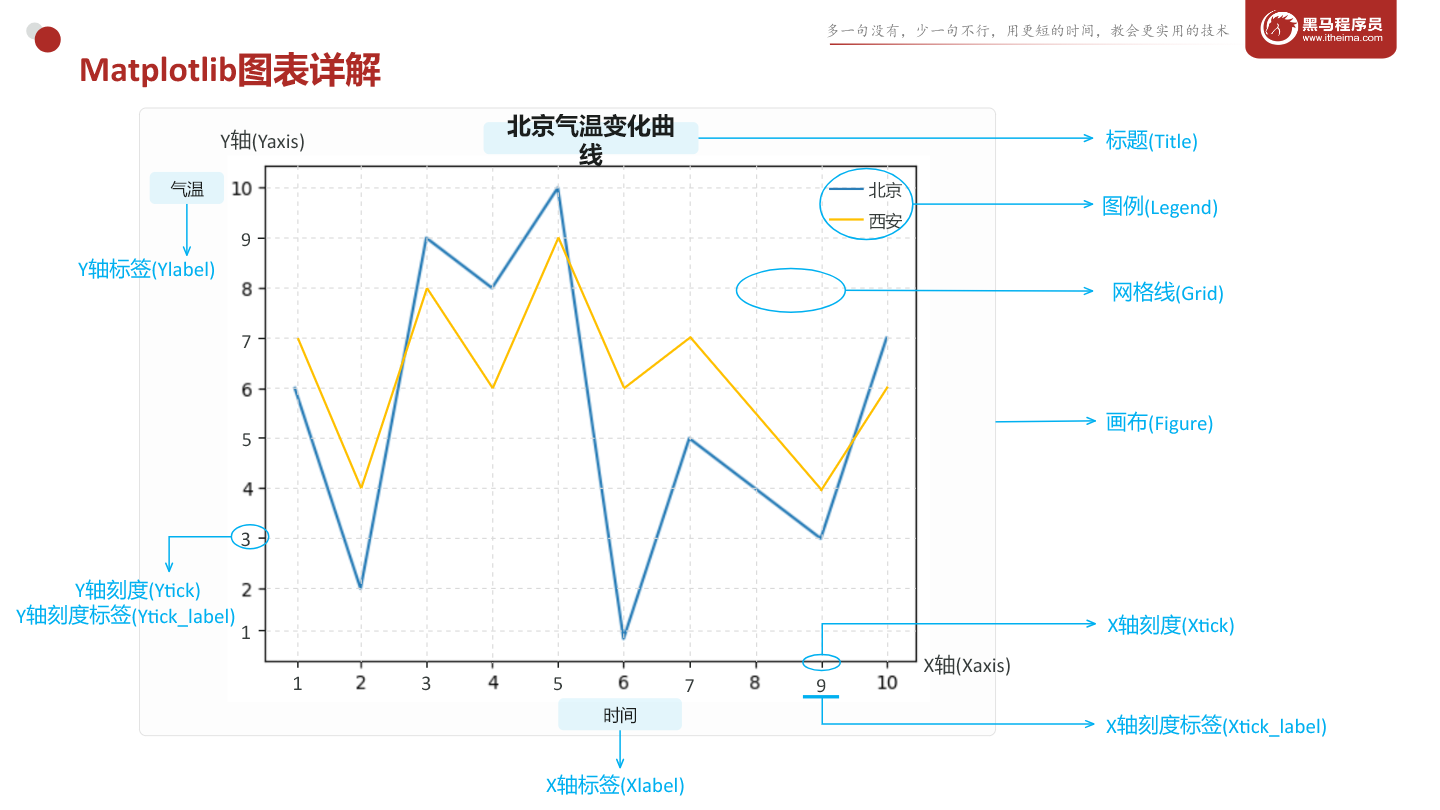

*讲义对图表组成的标注：画布、坐标轴、标题、刻度、标签、网格与图例。*

| 名称 | 含义 | 常见设置 |
| --- | --- | --- |
| Figure | 整张图的画布，可容纳一个或多个子图 | `plt.figure(...)`、`plt.subplots(...)` |
| Axes | 一个具体的绘图区，补充用于理解子图 | `ax.plot(...)`、`ax.bar(...)` |
| XAxis / YAxis | 绘图区的横轴、纵轴 | 显示范围、刻度与轴标签 |
| Title | 标题 | `plt.title(...)` 或 `ax.set_title(...)` |
| XLabel / YLabel | 横轴、纵轴的含义与单位 | `xlabel/ylabel` 或 `set_xlabel/set_ylabel` |
| XTick / YTick | 轴上的刻度位置 | `xticks/yticks` |
| Tick label | 刻度位置对应的文字 | 如日期、城市名或数值 |
| Grid | 辅助阅读数值的网格 | `grid(...)` |
| Legend | 说明不同线或颜色代表什么 | `legend(...)` |
| label | 某条线或某组数据的名称 | 绘图时指定，用于生成图例 |

**补充：**Axes 和 Axis 的名字相近。Axes 通常指一块完整绘图区，里面可以有横轴、纵轴；Axis 指其中的一条坐标轴。后面变量名 `axes` 通常是多个 Axes 组成的数组。

## 十三、气温折线图：标题、刻度、网格与图例

### 1. 课件示例的完整可运行写法

课件生成 1—24 时两座城市的气温序列，用两条折线放在同一个图中。北京取 10—15 的随机整数，西安取 15—19 的随机整数；它们是模拟数据。

下面保留截图中的主要绘图代码，**补充导入、固定随机种子、画布尺寸与布局设置**，并在标题中注明模拟数据：

```python
import random
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
# 补充：固定种子方便复现。两组数都是模拟值，不是实测天气。
random.seed(42)
x = range(1, 25)
y_beijing = [random.randint(10, 15) for i in range(len(x))]
y_xa = [random.randint(15, 19) for i in range(len(x))]

plt.figure(figsize=(12, 5))
plt.plot(x, y_beijing, label="北京")
plt.plot(x, y_xa, label="西安")
plt.title("气温变化曲线（模拟数据）")
plt.xlabel("时间 / 小时")
plt.ylabel("气温 / ℃")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right")
plt.xticks(x[::1])
plt.yticks(range(5, 25))
plt.tight_layout()
plt.show()
```

### 2. 按步骤理解

| 代码 | 作用 |
| --- | --- |
| `range(1, 25)` | 生成 1 到 24，不包含 25 |
| `random.randint(10, 15)` | 生成包含 10 和 15 的随机整数 |
| `label="北京"` | 为对应折线设置名字 |
| `plt.title` | 设置整块绘图区的标题 |
| `plt.xlabel / ylabel` | 说明横纵轴含义与单位 |
| `grid(True, linestyle="--", alpha=0.5)` | 显示透明度为 0.5 的虚线网格 |
| `legend(loc="upper right")` | 在右上角显示图例 |
| `xticks(x[::1])` | 每个小时都显示一个刻度 |
| `yticks(range(5, 25))` | 纵轴刻度为 5 到 24，步长为 1 |
| `tight_layout()` | 调整边距，减轻标题或标签重叠 |

**勘误：**课件截图中 `plt.yticks(range(5, 25))` 的注释写着“以 0 开始，步长为 2”，与代码不符。代码实际从 5 开始、步长为 1；若想从 0 开始、每 2 个单位一个刻度，应写 `range(0, 25, 2)`。

### 3. 中文字体与负号

课件使用 `SimHei` 显示中文。字体名称只有在当前系统安装了对应字体时才有效。

**补充：**本笔记在 Windows 上优先使用 `Microsoft YaHei`，其次 `SimHei`。`DejaVu Sans` 是后备字体，但它本身不能保证覆盖中文。若仍出现方框或缺字警告，需要换成机器上已有的中文字体。

`axes.unicode_minus = False` 让负数刻度使用普通连字符，常用于解决所选字体缺少 Unicode 负号的问题。

下图是运行上述固定种子代码生成的结果：

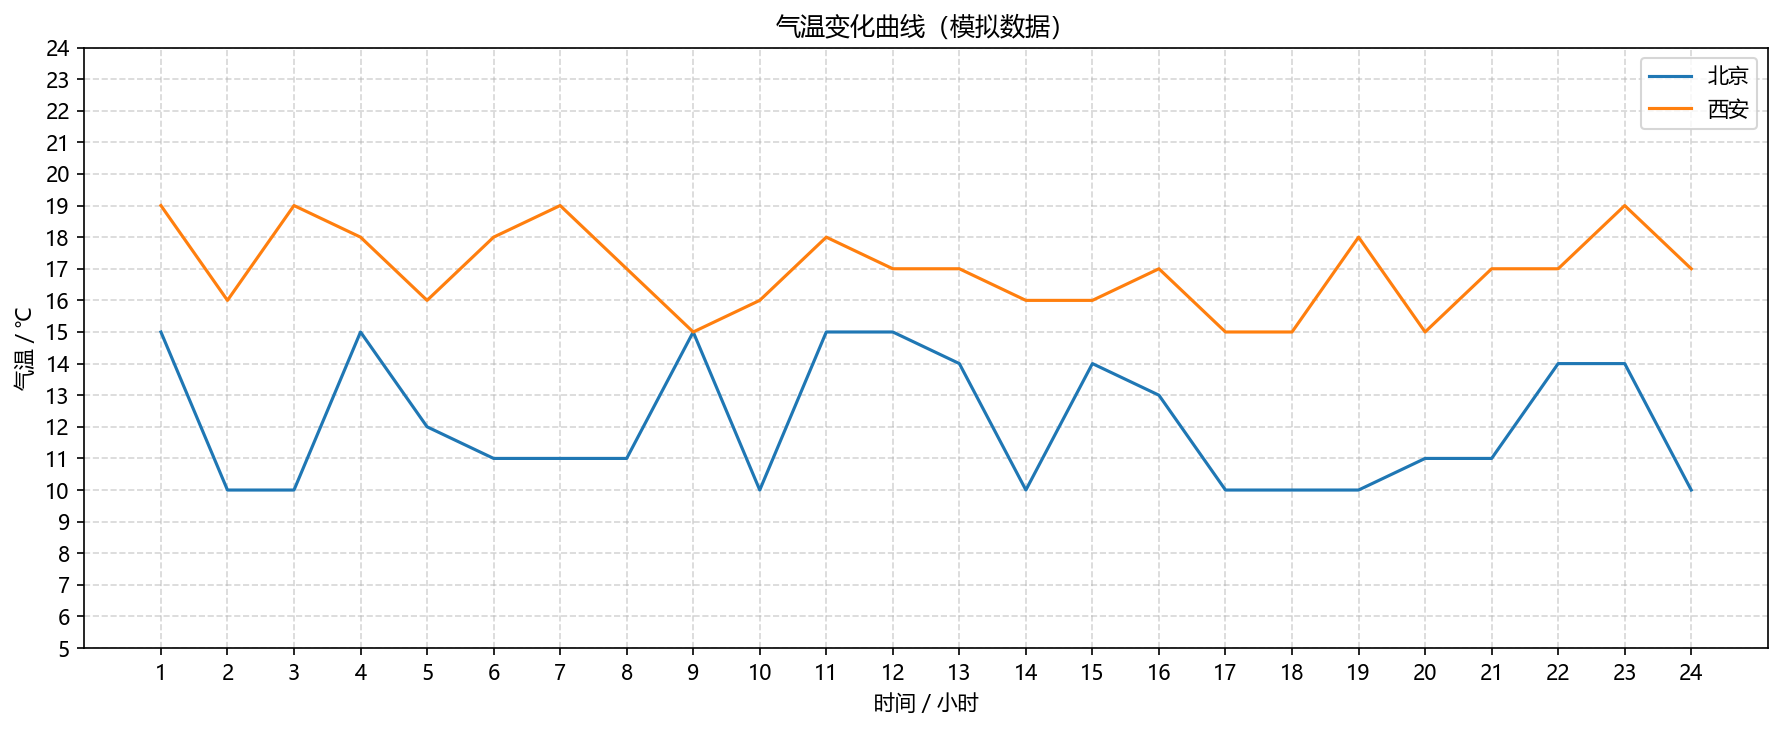

*补充示例输出：模拟的北京与西安 24 小时气温，不是实际天气记录。*

本节复习：数据系列名称通过 `label` 指定，图例通过 `legend` 显示；轴标题与轴刻度是不同内容；一张图内可以连续调用两次 `plot` 绘制两条线。

## 十四、创建子图与选择图形

### 1. 为什么需要子图

为了同时展示多个指标，便于直观对比，通常在一个 Figure 中创建多个 Axes。每块 Axes 可以有自己的数据、标题、坐标轴和图例。

讲义的一行两列布局：

```python
import matplotlib.pyplot as plt

figure, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 6), dpi=100)
axes[0].set_title("第一个子图")
axes[1].set_title("第二个子图")
figure.tight_layout()
plt.show()
```

| 参数 / 返回值 | 含义 |
| --- | --- |
| `nrows` | 子图的行数 |
| `ncols` | 子图的列数 |
| `figsize=(20, 6)` | 画布宽 20 英寸、高 6 英寸 |
| `dpi=100` | 每英寸 100 个像素；通常名义画布为 2000 × 600 像素 |
| `figure` | 整个画布对象 |
| `axes` | 子图对象或子图对象数组 |

`figsize` 是整张画布的尺寸，不是每个子图各自 20 × 6 英寸。

### 2. 两行两列

```python
figure, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8), dpi=100)
axes[0, 0].set_title("左上")
axes[0, 1].set_title("右上")
axes[1, 0].set_title("左下")
axes[1, 1].set_title("右下")
figure.tight_layout()
plt.show()
```

索引从 0 开始，先写行，再写列。课件后面的四图看板就是这种结构。

**补充：返回形状。**默认情况下，1 × 1 布局返回单个 Axes；1 × 2 返回一维数组；2 × 2 返回二维数组。因此不能对所有情况都机械地使用 `axes[0, 0]`。如果希望始终得到二维数组，可以设置 `squeeze=False`：

```python
figure, axes = plt.subplots(1, 1, squeeze=False)
axes[0, 0].plot([1, 2, 3], [2, 4, 3])
plt.show()
```

### 3. 折线图、柱状图与饼图

| 图形 | 调用 | 适合回答的问题 | 本章用途 |
| --- | --- | --- | --- |
| 折线图 | `plot(x, y)` | 随有序变量怎样变化 | 每日销售额、按年份的电影数量 |
| 柱状图 | `bar(x, height)` | 各类别数量怎样比较 | 语言、电影类型、城市销售数量 |
| 饼图 | `pie(values)` | 各部分占整体多大比例 | 各评分电影比例、订单类别或支付方式比例 |

柱状图的柱高应对应统计后的数值，不要把原始明细不经汇总就当作城市总量。饼图要求各项值非负、总和大于零，而且“部分”应能构成你想分析的那个整体。

### 4. 在同一画布绘制柱状图与饼图

课件第 46 页给出 `axes[0].bar(...)` 与 `axes[1].pie(...)` 的布局。下面补齐数据和参数，形成可运行示例：

```python
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
categories = ["食品", "图书", "服装", "电子产品", "家居用品"]
orders = [3, 2, 2, 2, 1]

figure, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
axes[0].bar(categories, orders, color="orange")
axes[0].set_title("各类别订单数")
axes[0].set_xlabel("产品类别")
axes[0].set_ylabel("订单数 / 单")
axes[0].tick_params(axis="x", labelrotation=25)

axes[1].pie(
    orders, labels=categories,
    autopct="%1.1f%%", startangle=90,
)
axes[1].set_title("各类别订单比例")
axes[1].set_aspect("equal")

figure.tight_layout()
plt.show()
```

`labels` 是每块扇形的类别文字；`autopct="%1.1f%%"` 显示一位小数的百分比；`startangle=90` 改变起始角度。这里 10 个订单中有 3 个食品订单，因此食品占 30%。

### 5. 保存图片

**补充：**综合案例需要把图表保存为结果文件。先创建输出目录，再在 `show` 之前保存：

```python
from pathlib import Path
import matplotlib.pyplot as plt

Path("output").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([1, 2, 3], [3, 5, 4])
ax.set_title("Example")
fig.tight_layout()
fig.savefig("output/example.png", dpi=150, bbox_inches="tight")
plt.show()
```

`bbox_inches="tight"` 尽量把图外多余空白裁掉，并保留相关图形元素。需要保存哪张图，就对那个 `fig` 调用 `savefig`，多图时更清楚。批量生成图表后可调用 `plt.close(fig)` 释放对应画布。

本节复习：创建子图用 `plt.subplots`；访问方式看布局维度；绘图方法选择取决于问题；多张图放进同一画布时，优先使用明确的 `axes[行, 列]` 对象。

## 十五、综合案例一：TMDB-TOP300 电影数据分析

### 1. 讲义任务与字段

案例使用电影表完成四个统计任务：

| 需求 | 分组依据与指标 | 图形 |
| --- | --- | --- |
| 每一年上映的电影数量变化 | 按年份统计样本电影数，按年份排序 | 折线图 |
| 不同语言电影数量对比 | 按语言统计电影数 | 柱状图 |
| 不同类型电影数量对比 | 每部电影的类型拆分后分别计数 | 柱状图 |
| 各个评分的电影占比 | 按评分值计数，再计算比例 | 饼图 |

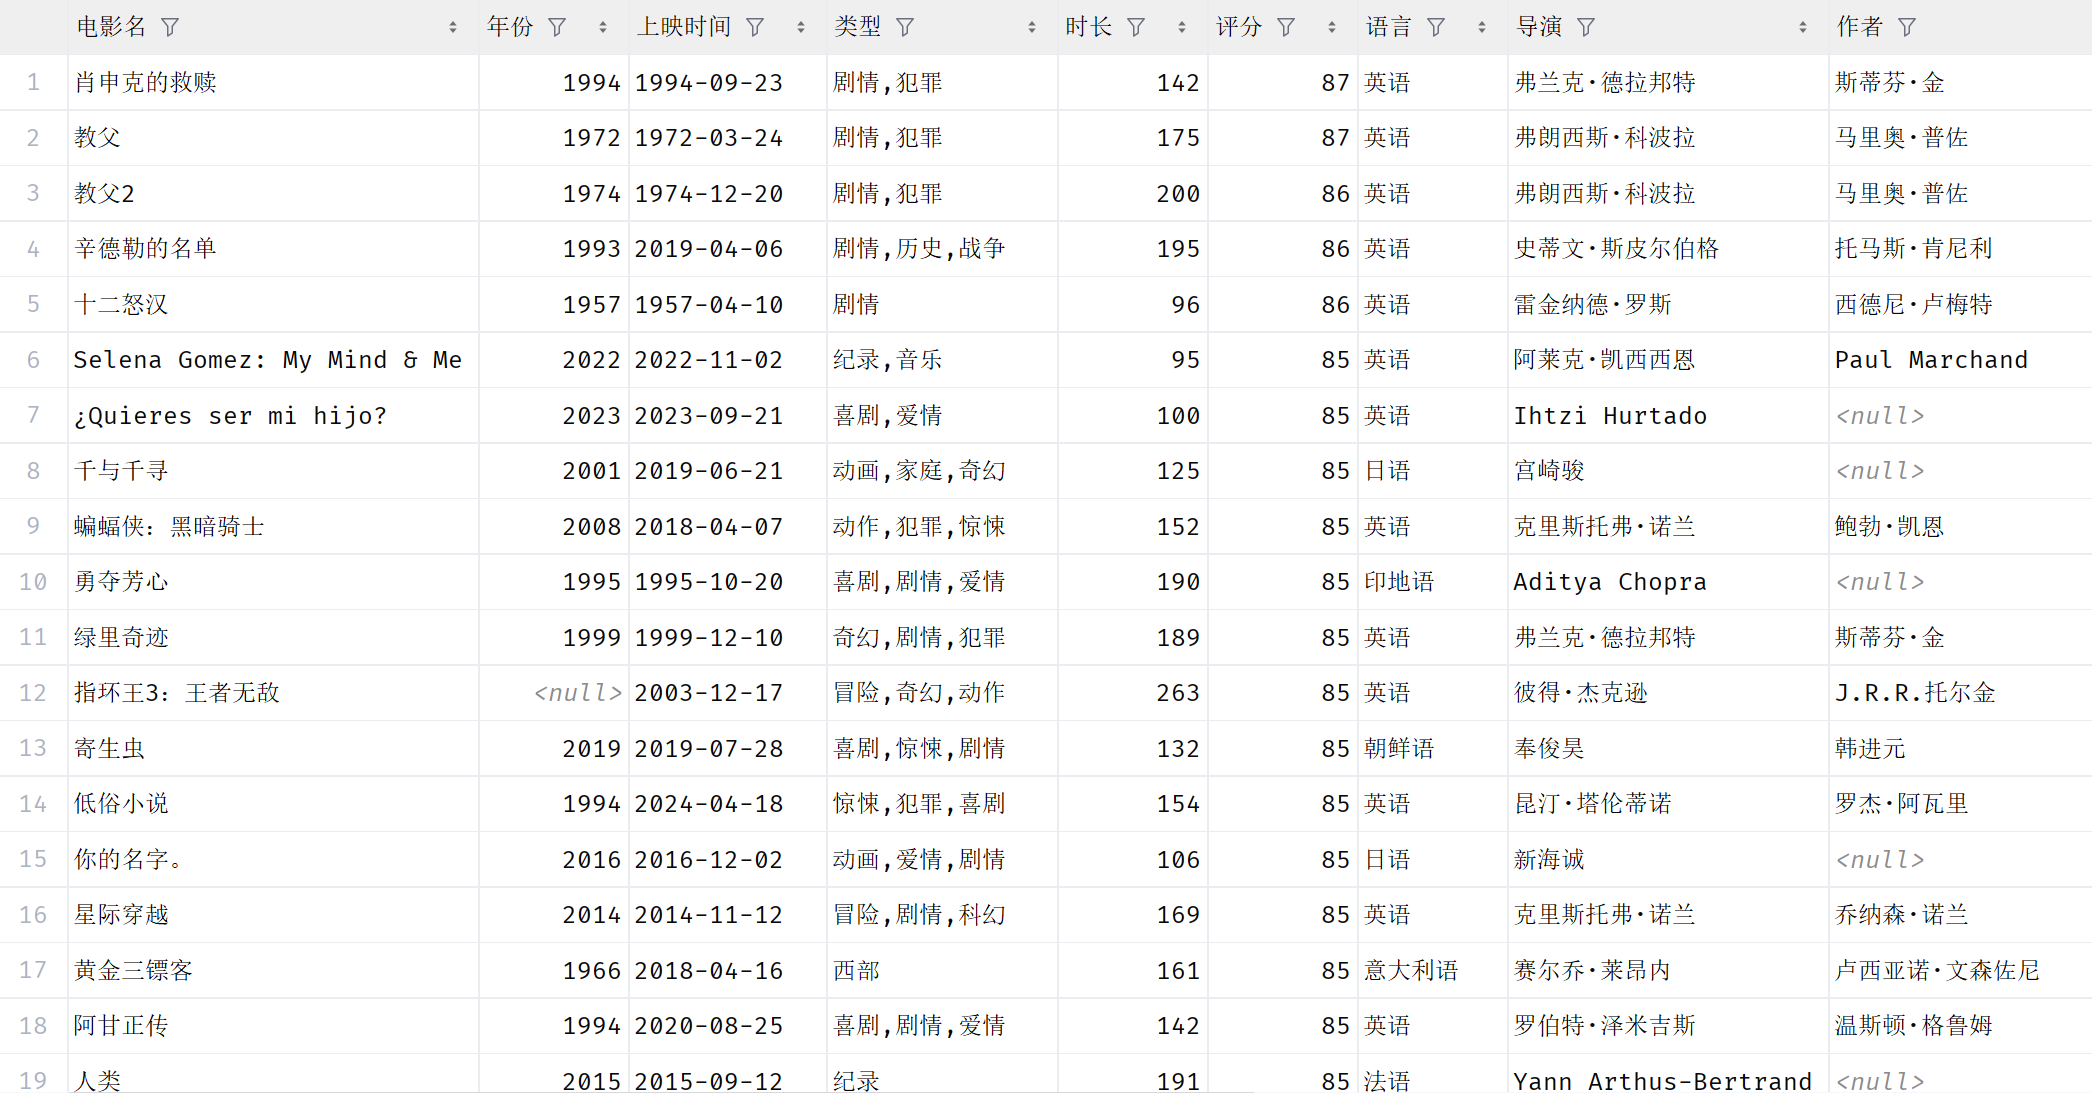

*讲义电影表截图：包含电影名、年份、上映时间、类型、时长、评分、语言、导演、作者等字段。*

| 字段 | 在本案例中的作用 |
| --- | --- |
| 电影名 | 识别展示记录；同名电影不一定是同一部电影 |
| 年份 | 年度电影数量统计 |
| 上映时间 | 更具体的日期；截图中可能是地区上映或重映日期 |
| 类型 | 一部电影可同时具有多个类型，如“剧情,犯罪” |
| 时长 | 电影长度，课件数据以分钟表示 |
| 评分 | 课件采用 87、86、85 这样的百分制数值 |
| 语言 | 按课件这一列的语言标签统计 |
| 导演、作者 | 电影资料字段，当前四幅图不直接使用 |

“年份”与“上映时间中的年份”不能随便互相替换。截图中《辛德勒的名单》的年份为 1993，上映时间是 2019 年的日期；《千与千寻》也有类似情况。若直接从“上映时间”提取年份，统计问题的含义可能变成另一个地区或另一次上映。

### 2. 目标效果与数据范围

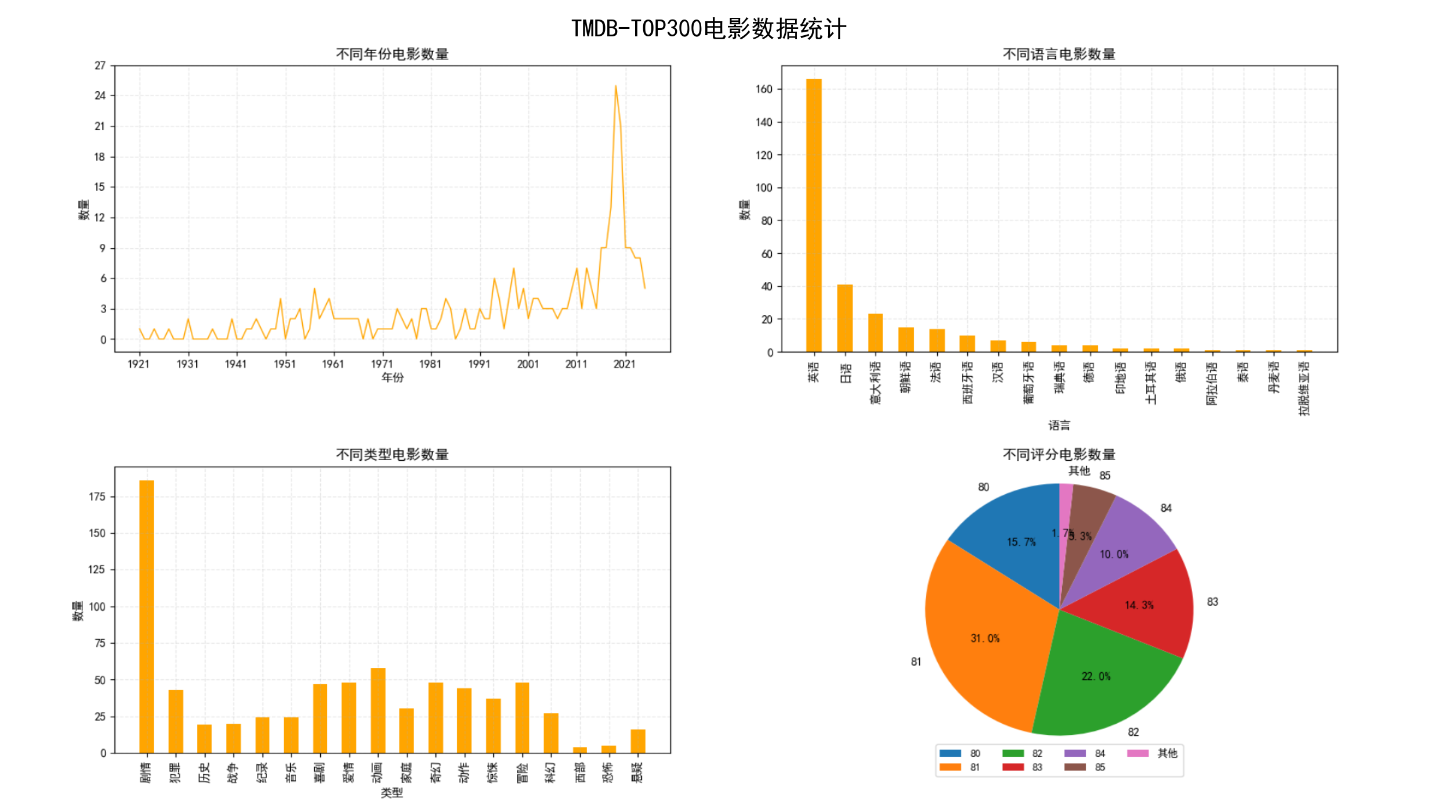

*讲义第 52 页的电影四图看板，页面标题使用 TMDB-TOP300；本图为课件效果展示。*

**勘误：**课件开头及复用的原始图里出现过“TOP200”，案例标题和任务使用“TOP300”。笔记以 TOP300 作为课程任务名；实际作图则明确写数据来源和有效电影数量，不能因为案例叫 TOP300 就把任意 CSV 当成正好 300 部。

年度图回答的是“这份榜单样本中的电影分布在哪些年份”。它不是该年全世界上映电影的总数，也不能直接代表整个电影行业的产量变化。

### 3. 按讲义步骤拆解

1. 导入 Pandas 与 Matplotlib，设置字体等绘图参数。
2. 加载电影 CSV，检查字段和缺失值。
3. 创建 2 × 2 子图布局。
4. 统计每个年份的电影数量并绘制折线图。
5. 统计不同语言的电影数量并绘制柱状图。
6. 拆分类型字段，统计类型数量并绘制柱状图。
7. 统计各评分的电影数量并绘制饼图。

课件给出了需求、步骤和效果，没有展示完整项目源码。下面的逐步代码与完整实现均为**补充参考实现**，用于把这四项任务实际跑通。

### 4. 生成电影练习 CSV

下面按课件截图前 19 行转写本案例会用到的 7 个字段。保留课件中的年份、语言和上映日期写法，不把这些历史截图当成实时的电影资料；《指环王3：王者无敌》的年份在原图中为空，也保留为空。

运行后生成 `data/movies_practice.csv`，已有同名文件时保留原内容。

```python
from pathlib import Path
import pandas as pd

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

# 补充练习素材：转写第 50 页截图的前 19 行，非完整或实时 TOP300。
movies = pd.DataFrame([
    ("肖申克的救赎", 1994, "1994-09-23", "剧情,犯罪", 142, 87, "英语"),
    ("教父", 1972, "1972-03-24", "剧情,犯罪", 175, 87, "英语"),
    ("教父2", 1974, "1974-12-20", "剧情,犯罪", 200, 86, "英语"),
    ("辛德勒的名单", 1993, "2019-04-06", "剧情,历史,战争", 195, 86, "英语"),
    ("十二怒汉", 1957, "1957-04-10", "剧情", 96, 86, "英语"),
    ("Selena Gomez: My Mind & Me", 2022, "2022-11-02", "纪录,音乐", 95, 85, "英语"),
    ("¿Quieres ser mi hijo?", 2023, "2023-09-21", "喜剧,爱情", 100, 85, "英语"),
    ("千与千寻", 2001, "2019-06-21", "动画,家庭,奇幻", 125, 85, "日语"),
    ("蝙蝠侠：黑暗骑士", 2008, "2018-04-07", "动作,犯罪,惊悚", 152, 85, "英语"),
    ("勇夺芳心", 1995, "1995-10-20", "喜剧,剧情,爱情", 190, 85, "印地语"),
    ("绿里奇迹", 1999, "1999-12-10", "奇幻,剧情,犯罪", 189, 85, "英语"),
    ("指环王3：王者无敌", None, "2003-12-17", "冒险,奇幻,动作", 263, 85, "英语"),
    ("寄生虫", 2019, "2019-07-28", "喜剧,惊悚,剧情", 132, 85, "朝鲜语"),
    ("低俗小说", 1994, "2024-04-18", "惊悚,犯罪,喜剧", 154, 85, "英语"),
    ("你的名字。", 2016, "2016-12-02", "动画,爱情,剧情", 106, 85, "日语"),
    ("星际穿越", 2014, "2014-11-12", "冒险,剧情,科幻", 169, 85, "英语"),
    ("黄金三镖客", 1966, "2018-04-16", "西部", 161, 85, "意大利语"),
    ("阿甘正传", 1994, "2020-08-25", "喜剧,剧情,爱情", 142, 85, "英语"),
    ("人类", 2015, "2015-09-12", "纪录", 191, 85, "法语"),
], columns=["电影名", "年份", "上映时间", "类型", "时长", "评分", "语言"])
movies["年份"] = movies["年份"].astype("Int64")

destination = data_dir / "movies_practice.csv"
if destination.exists():
    print("已有文件，保留原内容：", destination.resolve())
else:
    movies.to_csv(destination, index=False, encoding="utf-8-sig")
    print("已生成：", destination.resolve(), "行数：", len(movies))
```

`Int64` 是 Pandas 可容纳缺失值的整数类型。这里使用它，是为了把正常年份保存为 `1994`，同时允许另一行年份缺失，而不是被迫把年份都写成带小数点的形式。

### 5. 年份、语言与评分怎样统计

下面这段只演示该小样本的统计表达式；下一节的完整程序会增加对括号年份、空字符串、无效评分等情况的处理。

```python
import pandas as pd

movies = pd.read_csv("data/movies_practice.csv", encoding="utf-8-sig")
movies["年份"] = pd.to_numeric(movies["年份"], errors="coerce").astype("Int64")
movies["评分"] = pd.to_numeric(movies["评分"], errors="coerce")

year_counts = movies.dropna(subset=["年份"]).groupby("年份").size().sort_index()
language_counts = movies["语言"].fillna("未知").value_counts()
score_counts = movies["评分"].dropna().value_counts().sort_index()

print(year_counts)
print(language_counts)
print(score_counts)
```

- `groupby("年份").size()` 得到各年份有多少行电影记录。
- `sort_index()` 按年份标签排序，保证折线按时间从早到晚连接。
- `value_counts()` 统计某列各个值的出现次数，默认按次数从多到少排列。
- 对评分再 `sort_index()`，可以按分值从低到高组织饼图数据。

此处按每个具体评分值计算比例，例如 85 分的电影占多少，并没有把分数自行分成“优秀、良好”等区间。

**关于缺失：**年度统计只排除年份无效的记录；语言统计可以把缺失归为“未知”；评分饼图只在有效评分中计算比例。因此每张图要说明自己的有效样本量，不必因为某电影没有年份就把它从其他图中删除。

### 6. 多类型电影为什么必须拆分

一部电影的类型是 `"剧情,犯罪"` 时，如果直接对整列调用 `value_counts`，会统计“剧情,犯罪”这种**组合文本**出现了多少次，无法回答“剧情片共有多少部”。

讲义第 53 页用分离的类型文字强调这一点。需要把一部电影的一串类型变成多条“电影—类型”关系。

```python
type_demo = pd.DataFrame({
    "电影编号": [1, 2, 3],
    "类型": ["剧情,犯罪", "剧情, 历史,战争", "喜剧,剧情,剧情"],
})

expanded = type_demo.copy()
expanded["类型"] = expanded["类型"].str.split(",")
expanded = expanded.explode("类型")
expanded["类型"] = expanded["类型"].str.strip()
expanded = expanded.drop_duplicates(["电影编号", "类型"])
print(expanded)
print(expanded.groupby("类型").size())
```

拆分后的关系：

| 电影编号 | 类型 |
| --- | --- |
| 1 | 剧情 |
| 1 | 犯罪 |
| 2 | 剧情 |
| 2 | 历史 |
| 2 | 战争 |
| 3 | 喜剧 |
| 3 | 剧情 |

各步骤的意义：

1. `str.split(",")`：把字符串转成类型列表。
2. `explode`：把列表的每个元素展开成一行，电影编号随之保留。
3. `str.strip`：去掉类型名左右的空格。
4. 按“电影编号 + 类型”去重：第三部电影重复写了两次“剧情”，但只应算一次。
5. 按类型分组计数：剧情为 3，犯罪、历史、战争、喜剧各为 1。

**一部电影可以同时属于多个类型，所以类型计数总和可以大于电影总数。**这不等于产生了重复电影，也不适合直接当作互斥分类的电影比例饼图；本章按课件要求使用柱状图。

### 7. 完整参考程序

先运行本章的数据准备代码，再将下面内容复制到一个 Code 单元格，或保存成 `movie_analysis.py`。从包含 `data` 的学习目录运行。

程序会保留缺失年份记录用于其他统计，只在年度图中排除它；同一电影重复出现的同一类型只计一次。年份要求为四位数字，可带括号；评分按课件的 0—100 分范围处理。

```python
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

input_file = Path("data/movies_practice.csv")
output_dir = Path("output/movies")
output_dir.mkdir(parents=True, exist_ok=True)
dataset_label = "课件截图教学样例"

raw = pd.read_csv(
    input_file, dtype="string", encoding="utf-8-sig",
    na_values=["<null>", "null"],
)
required = ["电影名", "年份", "类型", "评分", "语言"]
missing_columns = set(required) - set(raw.columns)
if missing_columns:
    raise ValueError(f"缺少字段：{sorted(missing_columns)}")

df = raw.copy()
for column in required:
    df[column] = df[column].str.strip().replace("", pd.NA)

# 假设一行一部电影；只删除整行重复，不凭电影名删除可能的同名电影。
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
unnamed = df[df["电影名"].isna()].copy()
unnamed.to_csv(output_dir / "缺少电影名.csv", index=False, encoding="utf-8-sig")
df = df.dropna(subset=["电影名"]).copy()
df["_电影编号"] = range(len(df))
if df.empty:
    raise ValueError("没有可分析的电影记录，请检查 CSV。")

# 四位年份，可带括号；无效年份保留为缺失，不能由重映日期随意补齐。
year_text = df["年份"].str.replace(r"[()（）]", "", regex=True).str.strip()
valid_year_text = year_text.str.fullmatch(r"[0-9]{4}").fillna(False)
df["年份"] = pd.to_numeric(
    year_text.where(valid_year_text), errors="coerce"
).astype("Int64")

# 按课件的百分制评分处理；越界或无法转换的值不参与评分比例统计。
score = pd.to_numeric(
    df["评分"].str.replace("%", "", regex=False), errors="coerce"
)
df["评分"] = score.where(score.between(0, 100))

year_counts = df.dropna(subset=["年份"]).groupby("年份").size().sort_index()
language_counts = df["语言"].fillna("未知").value_counts()

# 一部电影可有多种类型：拆分、展开、清理空标签，同片同类型只计一次。
types = df[["_电影编号", "类型"]].copy()
types["类型"] = types["类型"].str.replace("，", ",", regex=False).str.split(",")
types = types.explode("类型")
types["类型"] = types["类型"].str.strip().replace("", pd.NA)
types = types.dropna(subset=["类型"]).drop_duplicates(["_电影编号", "类型"])
type_counts = types.groupby("类型").size().sort_values(ascending=False)
score_counts = df["评分"].dropna().value_counts().sort_index()

# 保存表格，便于对照图表核验数值。
df.to_csv(output_dir / "清洗后电影.csv", index=False, encoding="utf-8-sig")
for filename, counts in [
    ("按年份电影数量.csv", year_counts),
    ("按语言电影数量.csv", language_counts),
    ("按类型电影数量.csv", type_counts),
    ("按评分电影数量.csv", score_counts),
]:
    counts.rename("电影数量").to_csv(output_dir / filename, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=120)
fig.suptitle(f"电影数据分析｜{dataset_label}｜{len(df)} 部", fontsize=18)

ax = axes[0, 0]
if not year_counts.empty:
    ax.plot(year_counts.index.astype(int), year_counts.values,
            marker="o", color="#3776ab")
ax.set_title(f"样本中各年份电影数量（年份有效 {int(year_counts.sum())} 部）")
ax.set_xlabel("电影年份")
ax.set_ylabel("电影数量 / 部")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(alpha=0.3)

ax = axes[0, 1]
ax.bar(language_counts.index, language_counts.values, color="#ec9b32")
ax.set_title("各语言电影数量（缺失归为未知）")
ax.set_ylabel("电影数量 / 部")
ax.tick_params(axis="x", labelrotation=35)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax = axes[1, 0]
ax.bar(type_counts.index, type_counts.values, color="#48a696")
ax.set_title("各类型电影数量（同一电影可计入多个类型）")
ax.set_ylabel("电影数量 / 部")
ax.tick_params(axis="x", labelrotation=55)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

ax = axes[1, 1]
if score_counts.empty:
    ax.text(0.5, 0.5, "没有有效评分", ha="center", va="center")
else:
    score_labels = [f"{float(value):g} 分" for value in score_counts.index]
    ax.pie(score_counts.values, labels=score_labels, autopct="%1.1f%%",
           startangle=90, colors=plt.cm.Set2.colors)
ax.set_title(f"各评分电影比例（有效评分 {int(score_counts.sum())} 部）")
ax.set_aspect("equal")

fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(output_dir / "电影数据分析.png", dpi=160, bbox_inches="tight")
print({
    "原始行数": len(raw), "整行重复": duplicate_count,
    "缺少电影名": len(unnamed), "有效电影记录": len(df),
    "年份缺失或无效": int(df["年份"].isna().sum()),
    "评分缺失或无效": int(df["评分"].isna().sum()),
    "类型缺失": int(len(df) - types["_电影编号"].nunique()),
})
print("年份统计：\n", year_counts)
print("语言统计：\n", language_counts)
print("类型统计：\n", type_counts)
print("评分统计：\n", score_counts)
plt.show()
```

程序中需要特别理解：

| 写法 | 为什么这样做 |
| --- | --- |
| `dtype="string"` | 先按文本读取，避免类型推断掩盖特殊写法 |
| `na_values=["<null>", "null"]` | 把课件式的空值标记识别为缺失 |
| `drop_duplicates()` | 只处理完全相同的记录，不因同名误删另一部电影 |
| `_电影编号` | 给当前有效行分配临时标识，用于同片类型去重，不是 TMDB 官方 ID |
| `year_text.where(valid_year_text)` | 非四位年份不参与年度统计 |
| `score.where(score.between(0, 100))` | 不把越界分数作为有效评分画图 |
| `explode` | 把多类型电影转成长表 |
| `MaxNLocator(integer=True)` | 让电影数量坐标尽量使用整数刻度 |
| `fig.suptitle` | 为整个四图画布设置大标题 |
| `fig.tight_layout(rect=...)` | 为画布大标题预留空间 |
| `to_csv` 和 `savefig` | 同时留下可核查的统计表和图片 |

此实现按课件的语言字段“一行一个语言标签”统计；如果拿到的实际文件把多种语言也放在同一个字段，应先明确是统计主要语言还是所有语言，不能直接套用单标签口径。

### 8. 样例输出与核验

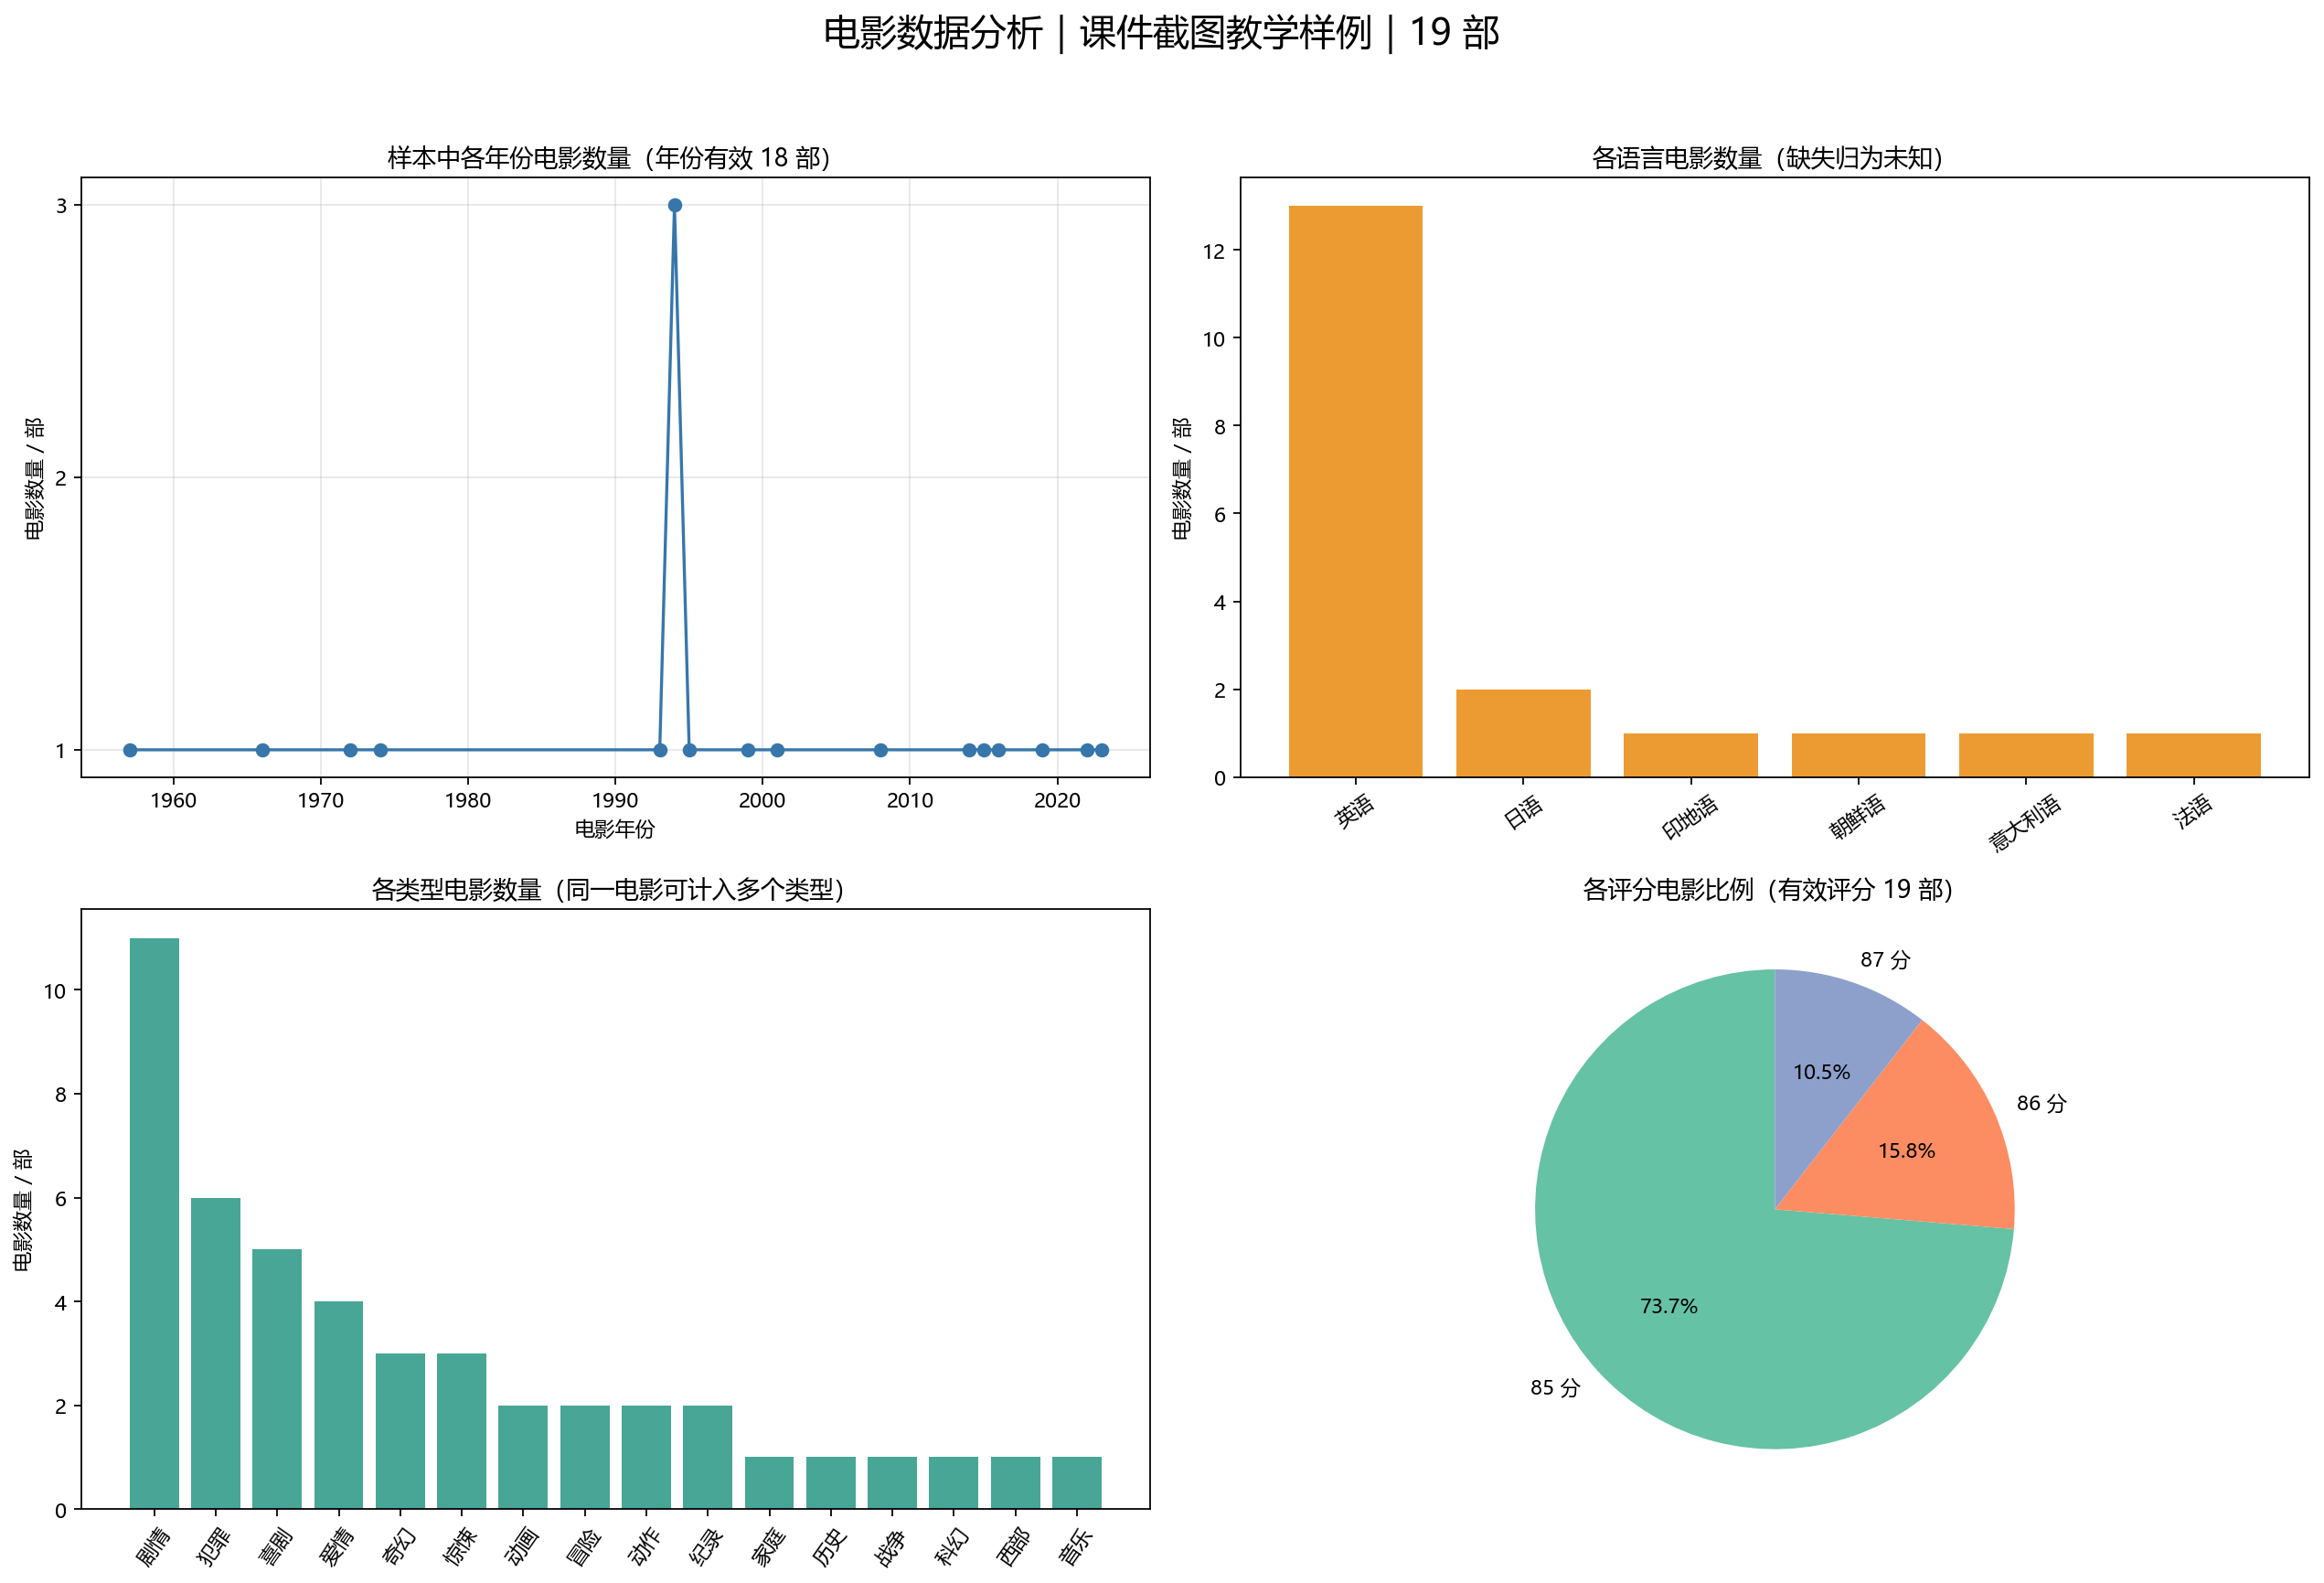

*补充参考程序的实际输出：19 条课件截图电影记录；其中 18 条年份有效，评分有效 19 条。*

核验结果：

| 指标 | 结果 | 含义 |
| --- | ---: | --- |
| 电影记录 | 19 | 小样本规模，不是 TOP300 完整数据 |
| 年份有效 | 18 | 有 1 条缺失年份，年度统计计数总和应为 18 |
| 1994 年电影 | 3 | 肖申克的救赎、低俗小说、阿甘正传 |
| 英语电影 | 13 | 依据课件语言字段 |
| 日语电影 | 2 | 依据课件语言字段 |
| 其他语言 | 各 1 | 印地语、朝鲜语、意大利语、法语 |
| 85 分电影 | 14 | 占有效评分电影的 73.7% 左右 |
| 86 分电影 | 3 | 占 15.8% 左右 |
| 87 分电影 | 2 | 占 10.5% 左右 |
| 类型计数总和 | 46 | 一部电影可能属于多个类型 |
| 剧情类型 | 11 | 同一部电影重复的“剧情”标签只算一次 |

程序保存的文件位于 `output/movies`：

- `清洗后电影.csv`：保留清洗后的值与临时电影编号。
- `缺少电影名.csv`：记录缺少关键标识的行，本练习为空表。
- `按年份电影数量.csv`、`按语言电影数量.csv`、`按类型电影数量.csv`、`按评分电影数量.csv`：四幅图的数据依据。
- `电影数据分析.png`：最终看板。

由于分组后 Series 的索引本身就是“年份、语言、类型或评分”，这里导出统计表时保留索引是有意义的；它与前面导出明细时排除无业务意义的默认行号不同。

### 9. 换成完整电影数据时

将 `input_file` 改成真实 CSV 路径，`dataset_label` 改成真实来源说明。然后确认：

1. 列名是否对应“电影名、年份、类型、评分、语言”；不同来源的“年代”等名称要显式重命名。
2. 年份字段代表什么，上映日期是否存在地区或重映差异。
3. 评分是否为 0—100 制；如果是 0—10 制，应按来源统一口径并修改标签，不能混放。
4. 一行是否确实对应一部电影，是否有重复采集、分页重复或同名电影。
5. 原始行数、重复数、有效记录数与每张图的分母是否符合预期。

折线图只连接数据中实际有记录的年份。若要把中间未出现的年份补成零，前提是你已经确认这些年份在当前样本中确实没有电影，而不是采集缺漏；不要为了图形连续就擅自补全事实。

## 十六、综合案例二：连锁店销售订单统计

### 1. 讲义练习要求

| 需求 | 正确的统计操作 | 图形 |
| --- | --- | --- |
| 每天销售额变化 | 按日对数量 × 单价求和 | 折线图 |
| 不同城市累计销售数量 | 按城市对销售数量求和 | 柱状图 |
| 不同产品类型对应订单比例 | 按产品类别统计订单数 | 饼图 |
| 不同支付方式对应订单比例 | 按支付方式统计订单数 | 饼图 |

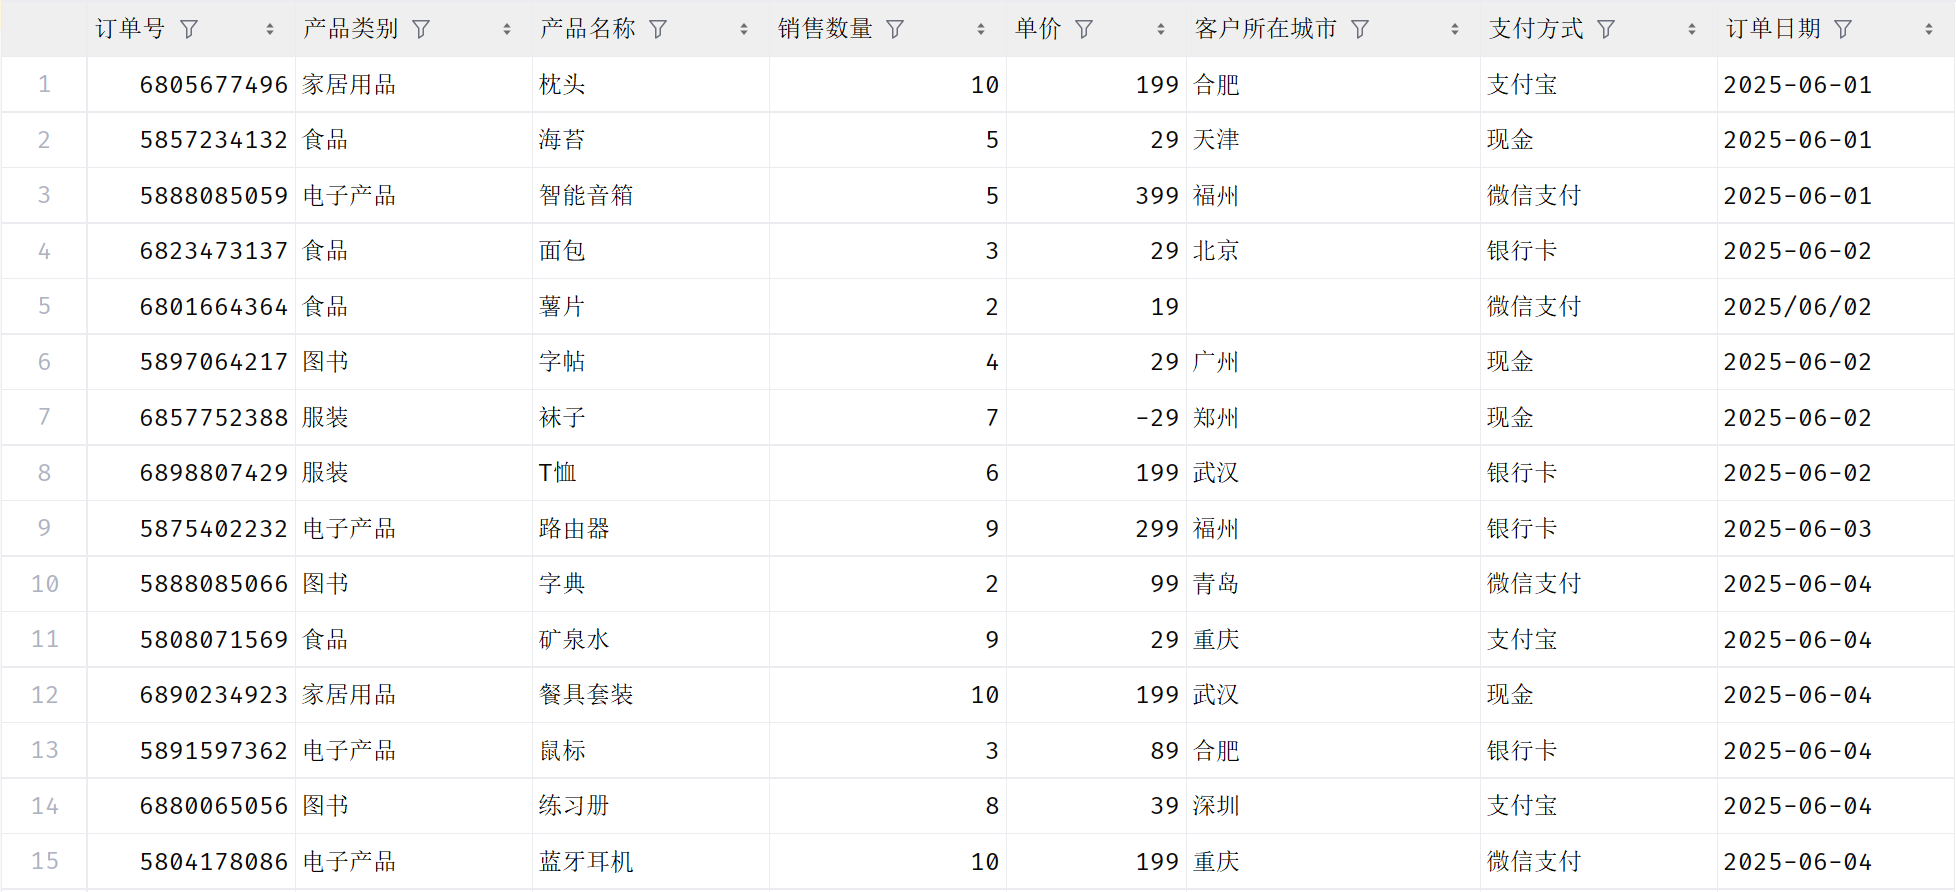

*讲义销售订单截图：练习使用其中前 10 行，并保留原图的缺失城市、负单价与日期格式差异。*

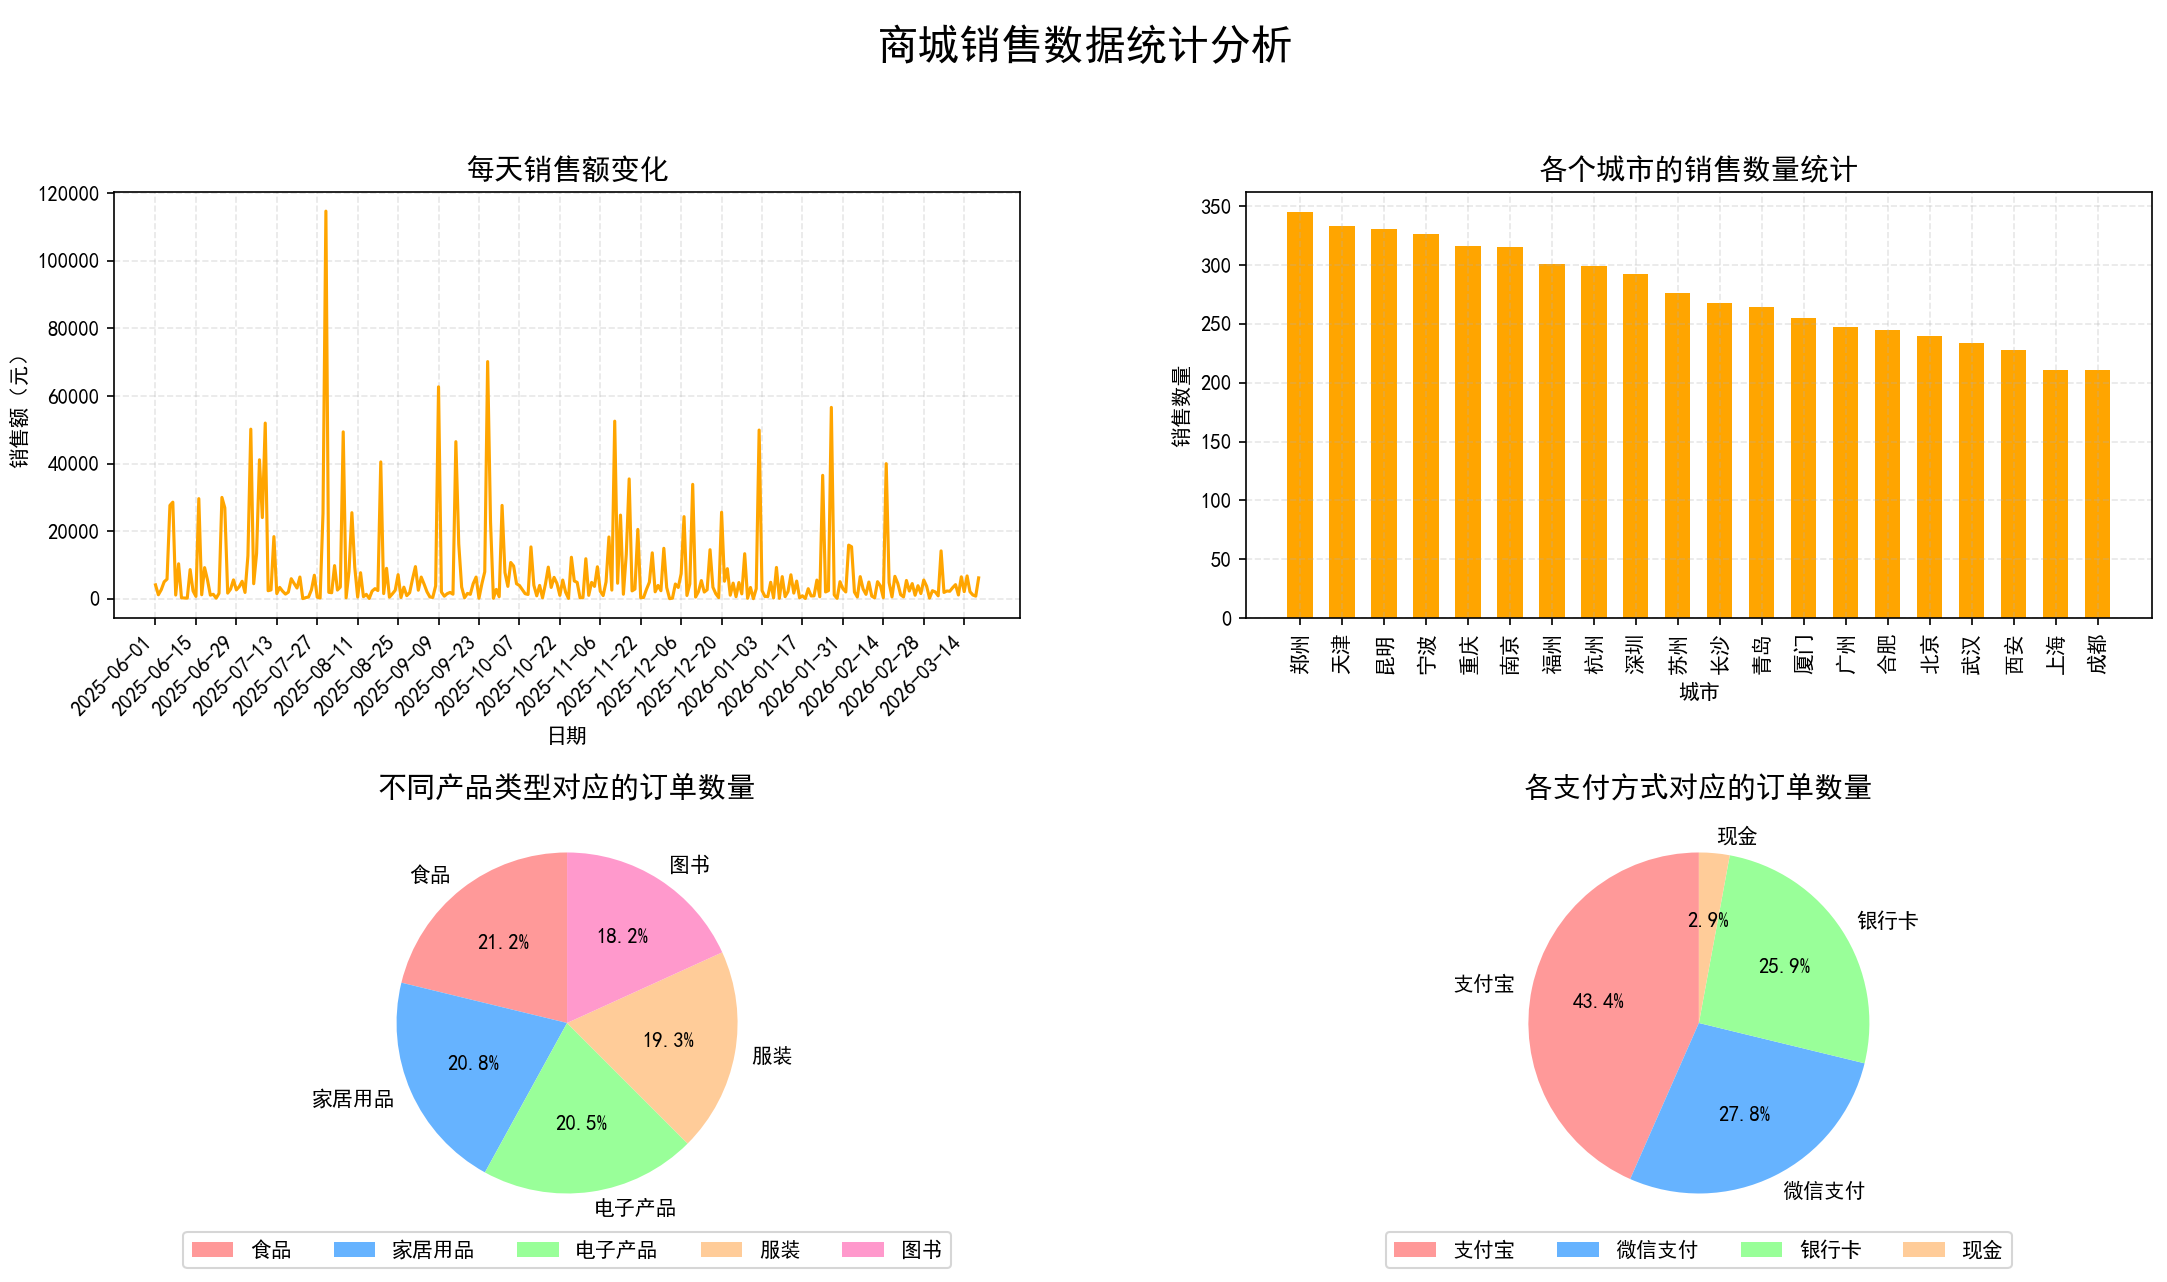

*讲义中完整销售数据的最终效果图；它与本笔记十行样例的规模和统计结果不同。*

### 2. 先确定数据粒度

下面参考程序采用教学约定：**一行是一张独立订单，每张订单只有一个产品类别和一种支付方式。**这与本笔记十行样例一致。

因此：

- 产品类别的各组订单数相加等于总订单数，可以画订单占比饼图。
- 支付方式的各组订单数相加也等于总订单数，可以画另一张饼图。
- 每单可能买多件商品，所以城市累计销售量使用 `销售数量.sum()`，不能用行数代替。

**补充：**真实订单明细可能一单多行、跨多个类别。即使各类别内对订单号 `nunique`，同一订单也可能同时进入多个类别，类别合计超过总订单数。这种情况适合比较“包含该类别的订单数”的柱状图，或先定义唯一主类别；不能直接把重叠计数当作互斥订单比例。

### 3. 四项统计的核心表达式

在第九节清洗后的 `df` 上：

```python
daily_sales = (
    df.groupby("订单日期")["销售额"].sum().sort_index()
)
city_quantity = (
    df.groupby("客户所在城市")["销售数量"]
    .sum().sort_values(ascending=False)
)
category_orders = (
    df.groupby("产品类别")["订单号"].nunique()
)
payment_orders = (
    df.groupby("支付方式")["订单号"].nunique()
)

print(daily_sales)
print(city_quantity)
print(category_orders)
print(payment_orders)
```

销售额计算的是商品数量与单价的乘积，示例中未包含优惠、税费、运费等另外的金额规则。真实业务如果有这些字段，应按实际销售额定义计算。

若“订单日期”包含时分秒，按日统计前可用 `dt.normalize()` 把时间归到当天零点。否则同一天的不同时间会被分到不同组；完整参考程序已包含这一步。

### 4. 完整参考程序

这是对课件练习的补充参考答案。重新从原始 `sales_practice.csv` 开始，完成清洗、核查、统计、绘图和导出，因此不依赖前面单元格中已有的 `df`。

对本样例，程序按课件后续表格把指定袜子订单单价改为 29，并将缺失城市归为“未知”。其余无法解析、负单价、非正或非整件数量等问题行会另存为待核查记录，不会静默改成零。分析范围是正常整件销售订单，退款或其他业务需要独立定义。

```python
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

input_file = Path("data/sales_practice.csv")
output_dir = Path("output/sales")
output_dir.mkdir(parents=True, exist_ok=True)
dataset_label = "课件截图教学样例"
# 只对本笔记提供的样例启用：第 35 页同笔订单单价为 29。
# 换成真实文件时设为 False，并按实际业务规则核实异常值。
apply_sample_correction = True

raw = pd.read_csv(
    input_file, dtype={"订单号": "string"}, encoding="utf-8-sig"
)
required = ["订单号", "产品类别", "产品名称", "销售数量", "单价",
            "客户所在城市", "支付方式", "订单日期"]
missing_columns = set(required) - set(raw.columns)
if missing_columns:
    raise ValueError(f"缺少字段：{sorted(missing_columns)}")

df = raw.copy()
for column in ["订单号", "产品类别", "客户所在城市", "支付方式"]:
    df[column] = df[column].astype("string").str.strip().replace("", pd.NA)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

for column in ["销售数量", "单价"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["订单日期"] = pd.to_datetime(
    df["订单日期"], format="mixed", errors="coerce"
).dt.normalize()

correction = (
    df["订单号"].eq("6857752388")
    & df["产品名称"].eq("袜子")
    & df["单价"].eq(-29)
).fillna(False)
correction_count = 0
if apply_sample_correction:
    correction_count = int(correction.sum())
    df.loc[correction, "单价"] = 29

df["客户所在城市"] = df["客户所在城市"].fillna("未知")
df["产品类别"] = df["产品类别"].fillna("未知")
df["支付方式"] = df["支付方式"].fillna("未知")

# 本练习分析正常、整件售出的销售订单：退货、无效数量等另存待核查。
bad = (
    df["订单号"].isna() | df["订单日期"].isna()
    | df["销售数量"].isna() | df["单价"].isna()
    | ~df["销售数量"].gt(0) | ~df["单价"].ge(0)
    | df["销售数量"].mod(1).ne(0)
).fillna(True)
issues = df.loc[bad].copy()
issues.to_csv(output_dir / "待核查记录.csv", index=False, encoding="utf-8-sig")
df = df.loc[~bad].copy()
if df.empty:
    raise ValueError("清洗后没有有效销售订单，请检查待核查记录。")

# 下面两个饼图要求一行一个独立订单、一个类别和一种支付方式。
# 同一订单多条明细时，先重新定义统计口径，不能随意删掉其余商品。
if df["订单号"].duplicated().any():
    raise ValueError("存在同订单多行数据，请先确认订单明细粒度和饼图口径。")

df["销售数量"] = df["销售数量"].astype(int)
df["销售额"] = df["销售数量"] * df["单价"]
daily = df.groupby("订单日期")["销售额"].sum().sort_index()
city = df.groupby("客户所在城市")["销售数量"].sum().sort_values(ascending=False)
category = df.groupby("产品类别")["订单号"].nunique().sort_values(ascending=False)
payment = df.groupby("支付方式")["订单号"].nunique().sort_values(ascending=False)

df.to_csv(output_dir / "清洗后销售.csv", index=False, encoding="utf-8-sig")
for filename, counts in [
    ("每日销售额.csv", daily), ("各城市销售数量.csv", city),
    ("各类别订单数.csv", category), ("各支付方式订单数.csv", payment),
]:
    counts.to_csv(output_dir / filename, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=120)
fig.suptitle(f"连锁店销售订单统计｜{dataset_label}｜{len(df)} 单", fontsize=18)
ax = axes[0, 0]
ax.plot(daily.index, daily.values, marker="o", color="#3776ab")
ax.set_title("每天销售额的变化")
ax.set_xlabel("订单日期")
ax.set_ylabel("销售额 / 元")
locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.grid(alpha=0.3)

ax = axes[0, 1]
ax.bar(city.index, city.values, color="#ec9b32")
ax.set_title("各城市累计销售数量")
ax.set_ylabel("销售数量 / 件")
ax.tick_params(axis="x", labelrotation=35)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

for ax, counts, title in [
    (axes[1, 0], category, "不同产品类别的订单比例"),
    (axes[1, 1], payment, "各支付方式的订单比例"),
]:
    ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%",
           startangle=90, colors=plt.cm.Set2.colors)
    ax.set_title(title)
    ax.set_aspect("equal")

fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(output_dir / "销售订单统计.png", dpi=160, bbox_inches="tight")
print({
    "原始行数": len(raw), "整行重复": duplicate_count,
    "按课件修正单价": correction_count, "待核查记录": len(issues),
    "有效订单数": len(df), "销售总量": int(df["销售数量"].sum()),
    "销售总额": float(df["销售额"].sum()),
})
print("每日销售额：\n", daily)
print("城市销售数量：\n", city)
print("类别订单数：\n", category)
print("支付方式订单数：\n", payment)
plt.show()
```

`apply_sample_correction=True` 仅用于本笔记提供的数据。替换真实 CSV 时设为 `False`，同时修改路径、来源标签，并按实际业务确认异常值的处理方式。

代码检查订单号是否重复：若发现同订单多条记录就停止，请先确认它们是重复导入还是合法的订单明细。这个检查是为了保证后面两个订单比例饼图符合已经声明的粒度。

### 5. 实际生成的看板

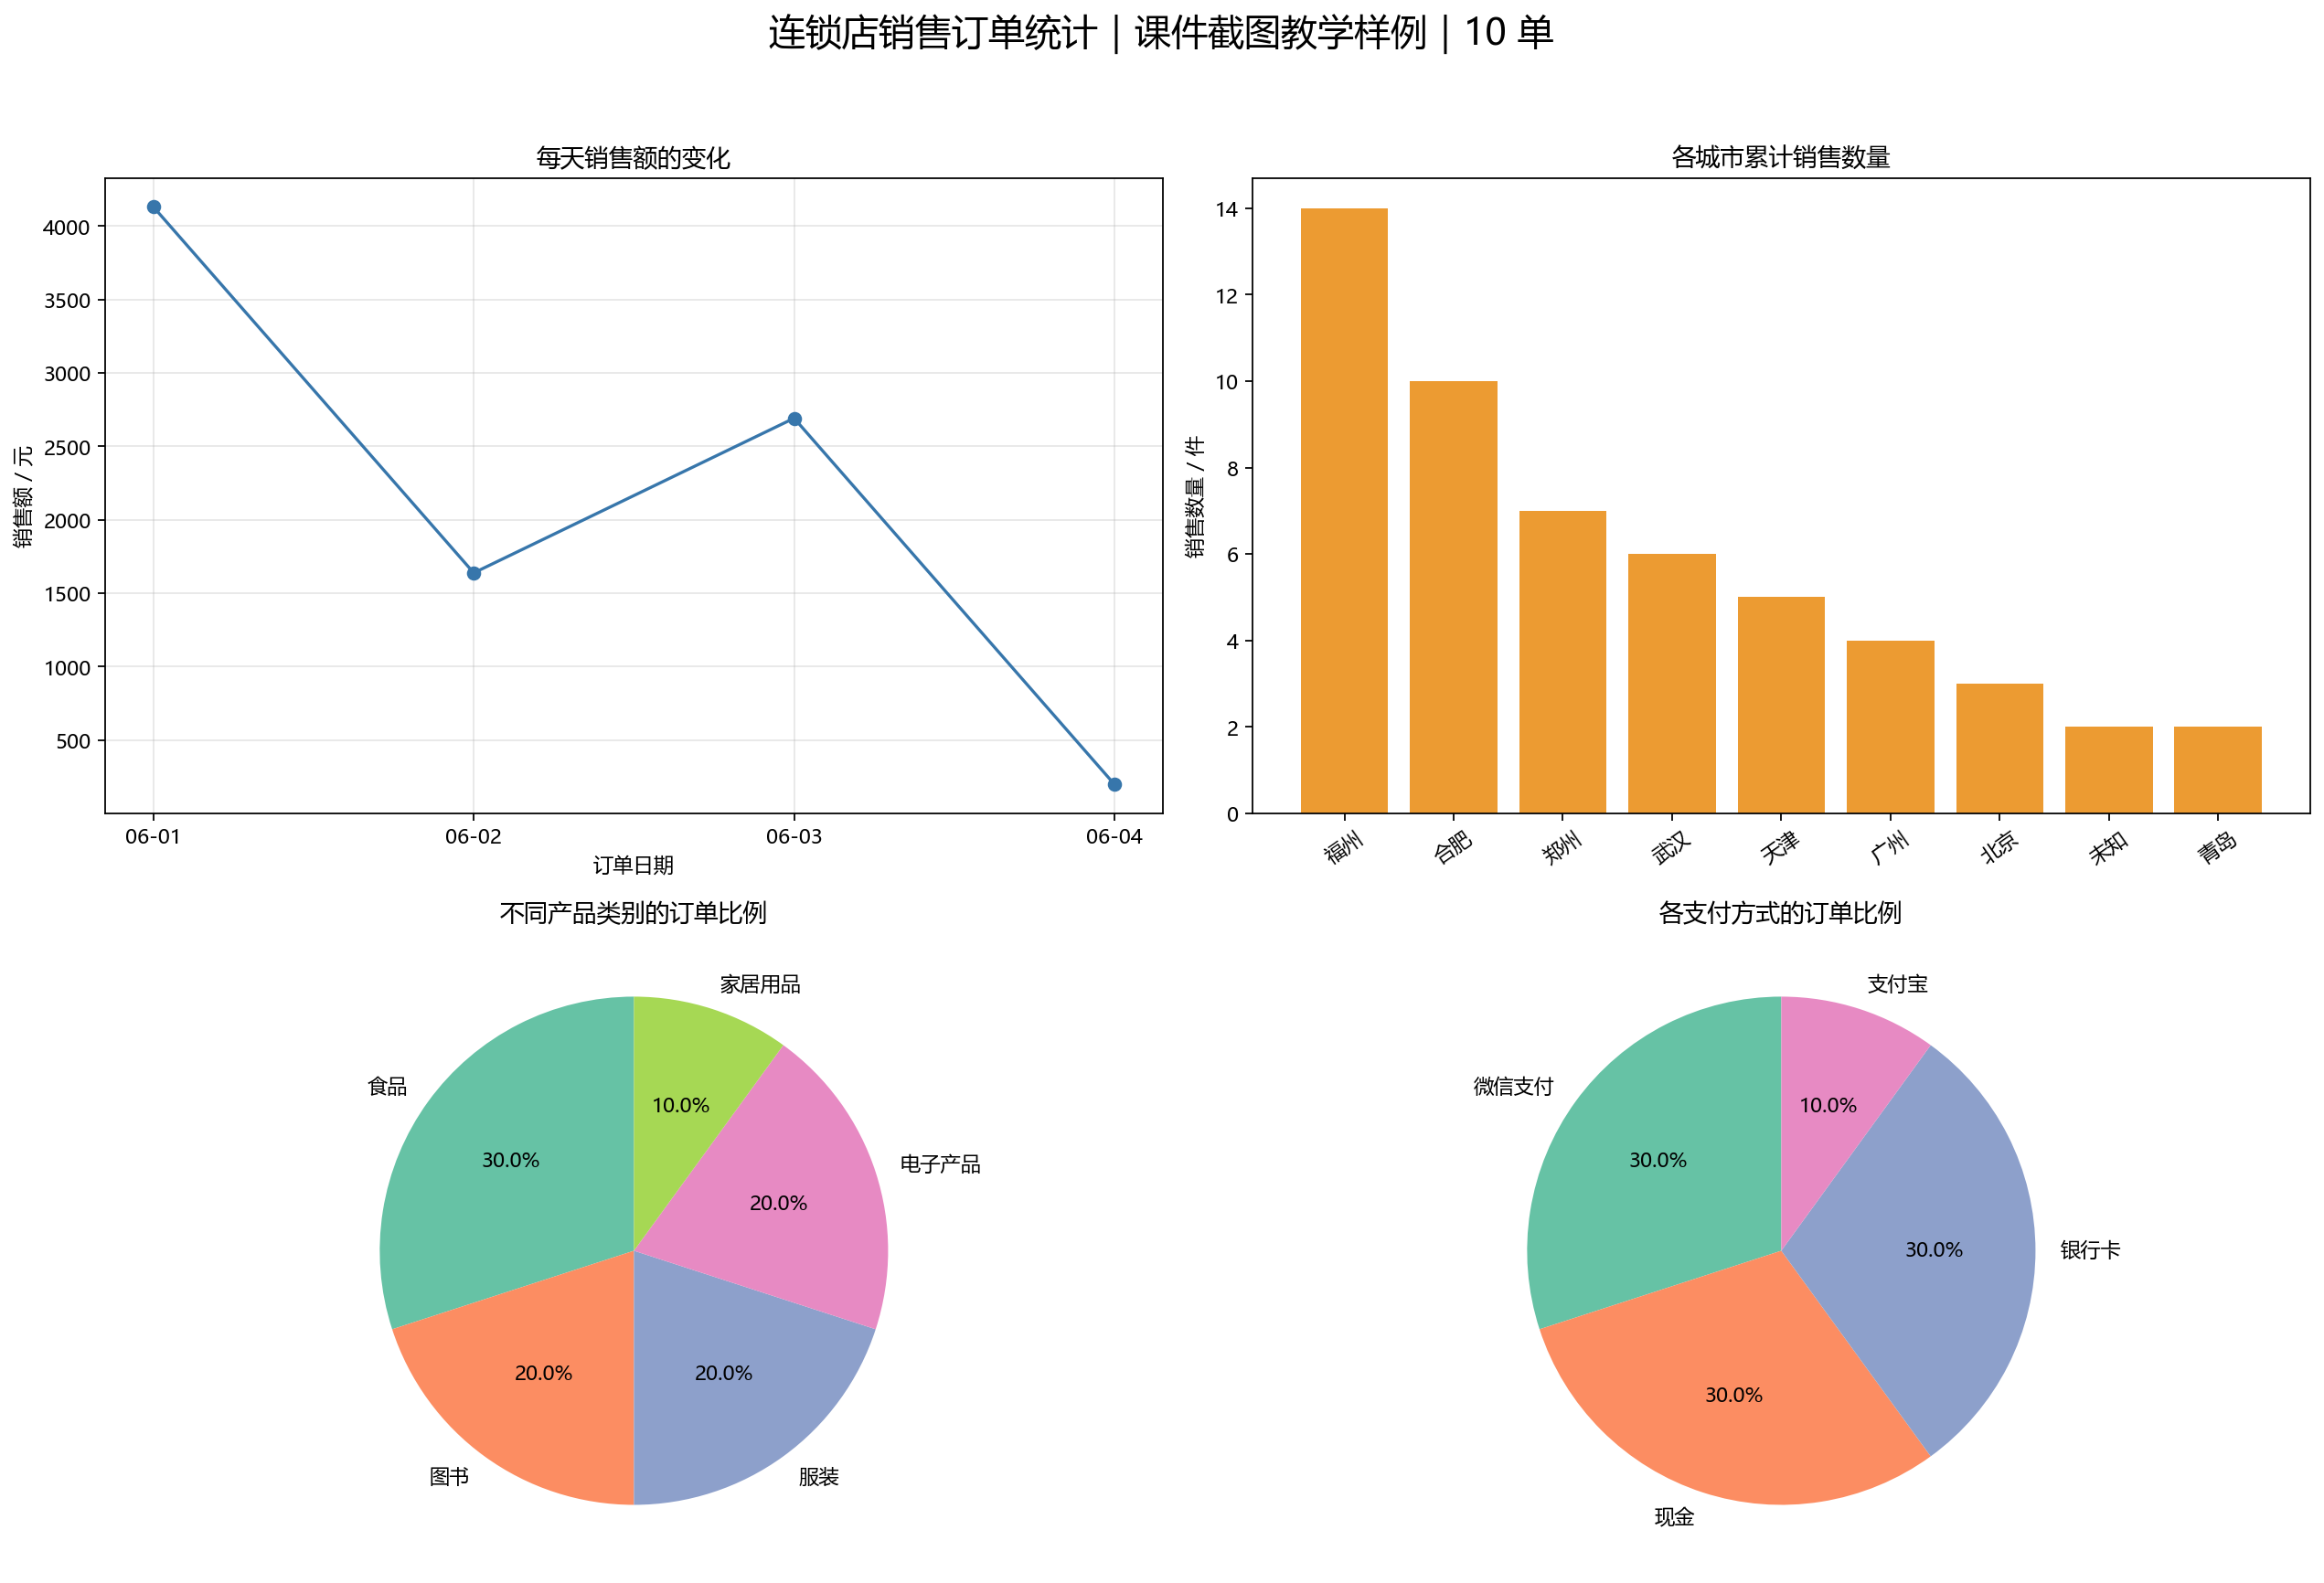

*补充参考程序的实际输出：10 单、53 件、销售额 8657 元；缺失城市单独记作“未知”。*

按日汇总：

| 日期 | 销售额 / 元 |
| --- | ---: |
| 2025-06-01 | 4130 |
| 2025-06-02 | 1638 |
| 2025-06-03 | 2691 |
| 2025-06-04 | 198 |
| 合计 | 8657 |

城市销售数量：

| 城市 | 销售数量 / 件 |
| --- | ---: |
| 福州 | 14 |
| 合肥 | 10 |
| 郑州 | 7 |
| 武汉 | 6 |
| 天津 | 5 |
| 广州 | 4 |
| 北京 | 3 |
| 青岛 | 2 |
| 未知 | 2 |
| 合计 | 53 |

两种订单比例：

| 分类维度 | 分类值 | 订单数 | 占比 |
| --- | --- | ---: | ---: |
| 产品类别 | 食品 | 3 | 30% |
| 产品类别 | 图书 | 2 | 20% |
| 产品类别 | 服装 | 2 | 20% |
| 产品类别 | 电子产品 | 2 | 20% |
| 产品类别 | 家居用品 | 1 | 10% |
| 支付方式 | 微信支付 | 3 | 30% |
| 支付方式 | 现金 | 3 | 30% |
| 支付方式 | 银行卡 | 3 | 30% |
| 支付方式 | 支付宝 | 1 | 10% |

同一个维度内部的占比合计为 100%；不能把“产品类别”和“支付方式”两种维度混在一起再求总比例。

### 6. 输出文件与核验顺序

`output/sales` 中包含：

- `清洗后销售.csv` 和 `待核查记录.csv`。
- `每日销售额.csv`、`各城市销售数量.csv`、`各类别订单数.csv`、`各支付方式订单数.csv`。
- `销售订单统计.png`。

建议按如下关系检查结果：

```text
每日销售额之和 = 清洗后明细的销售额之和 = 8657 元
各城市销售数量之和 = 清洗后明细的销售数量之和 = 53 件
各类别订单数之和 = 各支付方式订单数之和 = 10 单
各饼图内部比例之和 ≈ 100%（显示时可能存在四舍五入差异）
```

这比只看“程序没有报错、图已经画出来”更能确认分析过程可靠。

## 十七、本章知识串联与复习

### 1. 一次完整数据分析的顺序

```text
明确问题和指标
    ↓
读取文件，确认一行代表什么
    ↓
查看字段、类型、缺失值和异常值
    ↓
清洗数据，保留问题记录与处理依据
    ↓
选择、过滤、排序、分组聚合
    ↓
选择合适图形，写清标题、单位、样本范围
    ↓
核对汇总结果，再保存表格和图片
```

### 2. 常用操作速查

| 要做的事情 | 主要写法 |
| --- | --- |
| 构造二维表 | `pd.DataFrame(...)` |
| 构造一维数据 | `pd.Series(...)` |
| 读取 / 写出 CSV | `pd.read_csv(...)` / `df.to_csv(...)` |
| 读取 / 写出 Excel | `pd.read_excel(...)` / `df.to_excel(...)` |
| 查看前后记录 | `head(...)` / `tail(...)` |
| 看结构与分布 | `info()` / `describe()` / `shape` / `dtypes` |
| 选列 | `df["列"]` 或 `df[["列1", "列2"]]` |
| 按位置 / 标签选行 | `iloc` / `loc` |
| 筛选 | `df[条件]`、`isin`、`between` |
| 处理缺失 | `isnull`、`dropna`、`fillna`、`ffill`、`bfill` |
| 处理重复 | `duplicated`、`drop_duplicates` |
| 统一字符串 | `str.replace`、`str.strip` |
| 转成数值 / 日期 | `pd.to_numeric` / `pd.to_datetime` |
| 排序 | `sort_values`，对标签排序用 `sort_index` |
| 分组统计 | `groupby(...).sum/count/max/min/mean`、`agg` |
| 补充的计数方法 | `size`、`nunique`、`value_counts` |
| 拆分多值字段 | `str.split` 与 `explode` |
| 折线 / 柱状 / 饼图 | `plot` / `bar` / `pie` |
| 创建多个子图 | `plt.subplots(...)` |
| 保存图表 | `fig.savefig(...)` |

### 3. 用本章案例回答问题

1. **DataFrame 与 Series 的主要区别？**前者是二维表，后者是一维带索引数据；取一列常得到 Series。
2. **为什么读到数字还可能不能求和？**它可能实际是文本，需要检查类型与无法转换的内容。
3. **为什么不直接删除所有有缺失的行？**缺失字段不一定影响当前统计，应围绕具体任务判断。
4. **为什么重复订单号不一定是重复数据？**一张订单可能包含多条商品明细。
5. **为什么电影类型计数比电影数多？**同一电影可能进入多个类型，而各评分与单语言类别在当前口径下是一部电影对应一个值。
6. **为什么统计福州销售数量用 sum？**要数售出的件数；两张订单卖 5 件和 9 件，应是 14 件而不是 2 件。
7. **为什么平均单价和销售额除以销售数量不同？**前者默认每条记录等权，后者按售出件数加权。
8. **为什么需要按日期或年份排序后再画折线？**折线按传入数据的顺序连接，顺序错误会改变图形表达。
9. **什么时候订单占比饼图的分母可以使用总订单数？**每张订单在该分类维度下有且只有一个归属，分类之间不重叠。
10. **怎样判断案例做对了？**不仅能出图，还应满足明细与汇总总量一致、单位正确、样本范围和缺失处理明确。

### 4. 练习时常见问题

| 现象 | 优先检查 |
| --- | --- |
| `ModuleNotFoundError` | 包是否安装在当前内核对应的解释器中 |
| `FileNotFoundError` | 是否先生成了数据文件；当前工作目录与相对路径是否一致 |
| `KeyError` 找不到列 | 表头是否拼写一致，是否有空格或不同名称 |
| 多条件筛选报错 | 每个条件是否加括号，是否误用 and / or |
| “全部运行”与零散执行结果不同 | 是否存在旧变量、跳过的数据准备单元格 |
| 图中中文变方框 | 配置的中文字体是否真的安装 |
| 日期图顺序混乱 | 日期是否为真正的日期类型，是否排好序 |
| 计数、比例与预期不符 | 是否混淆件数、订单数与行数；是否丢掉了缺失分组或重复计入多个类别 |

本章素材来自 57 页 PPT。封面、目录与重复演示并入相应内容，末页品牌结束页未单独展开；目录页备注中沿用上一章“爬虫工作流程、robots”的文字属于模板残留，不作为本章新增知识。参考代码和样例图均与课件原图作了区分，便于以后替换真实数据继续练习。